In [2]:
import pandas as pd
import numpy as np
import re
import warnings
warnings.filterwarnings('ignore')

from urllib.parse import urlparse
from collections import Counter
import time

from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report
import xgboost as xgb

from XGBoost_model_feature_extraction import extract_features_vectorized, load_trusted_domains

import matplotlib.pyplot as plt
import seaborn as sns
from joblib import dump, load
import json
import sys
import os
import shap
from sklearn.inspection import partial_dependence, PartialDependenceDisplay
import shap


## 1. Data Loading


In [3]:
df = pd.read_csv('/Users/abdulsalamali/School/Dissertation/datasets/Dataset3.csv')
trusted_df = pd.read_csv('/Users/abdulsalamali/School/Dissertation/datasets/trusted_domains.csv')


## 2. Vectorized Feature Engineering (10x Faster)


In [4]:
trusted_domains_set = load_trusted_domains()
start_time = time.time()

X = extract_features_vectorized(df['url'], trusted_domains_set)
y = df['status'].values

end_time = time.time()

print(f"Features extracted: {len(X.columns)}")



Features extracted: 49


## 3. Model Training and Three-Threshold Optimization


In [5]:
# Data splitting
print("Splitting data...")
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y  
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.2, random_state=42, stratify=y_temp
)

print(f"Training set: {X_train.shape}, {Counter(y_train)}")
print(f"Validation set: {X_val.shape}, {Counter(y_val)}")
print(f"Test set: {X_test.shape}, {Counter(y_test)}")


Splitting data...
Training set: (594767, 49), Counter({np.int64(1): 304388, np.int64(0): 290379})
Validation set: (148692, 49), Counter({np.int64(1): 76097, np.int64(0): 72595})
Test set: (131199, 49), Counter({np.int64(1): 67145, np.int64(0): 64054})


In [6]:
start_time = time.time()

xgboost_model = xgb.XGBClassifier(
    n_estimators=200,  
    max_depth=8, 
    learning_rate=0.1,
    subsample=0.8, 
    colsample_bytree=0.8, 
    random_state=42, 
    n_jobs=-1
)

xgboost_model.fit(X_train, y_train)

y_pred_proba = xgboost_model.predict_proba(X_val)[:, 1]

auc_score = roc_auc_score(y_val, y_pred_proba)
training_time = time.time() - start_time

model_results = {
    'XGBoost': {
        'auc': auc_score,
        'probabilities': y_pred_proba,
        'training_time': training_time
    }
}

trained_models = {
    'XGBoost': xgboost_model
}

print(f"XGBoost - AUC: {auc_score:.4f}, Training time: {training_time:.1f}s")

# for compatibility older version
best_model_name = 'XGBoost'
best_model = xgboost_model
best_probabilities = y_pred_proba
# Save XGBoost model (simple approach like RF notebook)
dump(best_model, 'XGBoost_model.joblib')



XGBoost - AUC: 0.9830, Training time: 3.4s


['XGBoost_model.joblib']

In [7]:
def calculate_metrics_with_thresholds(y_true, y_proba, lower_threshold, upper_threshold):
   
    predictions = np.full(len(y_proba), 'human review')
    predictions[y_proba <= lower_threshold] = 'legitimate'
    predictions[y_proba >= upper_threshold] = 'phishing'
    
    legitimate_mask = (y_true == 0)
    phishing_mask = (y_true == 1)
    
    legitimate_predicted_phishing = np.sum((predictions == 'phishing') & legitimate_mask)
    legitimate_total = np.sum(legitimate_mask)
    fpr = legitimate_predicted_phishing / legitimate_total if legitimate_total > 0 else 0
    
    phishing_predicted_legitimate = np.sum((predictions == 'legitimate') & phishing_mask)
    phishing_total = np.sum(phishing_mask)
    fnr = phishing_predicted_legitimate / phishing_total if phishing_total > 0 else 0
    
    human_review_count = np.sum(predictions == 'human review')
    human_review_rate = human_review_count / len(predictions)
    
    return {
        'fpr': fpr,
        'fnr': fnr, 
        'human_review_rate': human_review_rate,
        'predictions': predictions
    }

# threshold optimisation with adaptive grid
def optimize_thresholds_fast(y_true, y_proba, target_fpr=0.02, target_fnr=0.02, target_human_review=0.05):
   
    best_score = float('inf')
    best_thresholds = None
    best_metrics = None
    
    # adaptive grid based on probability distribution
    p25, p50, p75 = np.percentile(y_proba, [25, 50, 75])
    
    lower_range = np.linspace(0.05, p50, 15) # creates 15 evenly spaced values between 0.05 and the 50th percentile
    upper_range = np.linspace(p50, 0.95, 15) # creates 15 evenly spaced values between the 50th percentile and 0.95
    
    print(f"Lower range: {lower_range[0]:.3f} to {lower_range[-1]:.3f}")
    print(f"Upper range: {upper_range[0]:.3f} to {upper_range[-1]:.3f}")
    print(f"Testing {len(lower_range)} x {len(upper_range)} = {len(lower_range) * len(upper_range)} combinations")
    
    for lower_thresh in lower_range:
        for upper_thresh in upper_range:
            if upper_thresh <= lower_thresh:
                continue
                
            metrics = calculate_metrics_with_thresholds(y_true, y_proba, lower_thresh, upper_thresh)
            
            fpr_penalty = abs(metrics['fpr'] - target_fpr)
            fnr_penalty = abs(metrics['fnr'] - target_fnr) 
            hr_penalty = abs(metrics['human_review_rate'] - target_human_review)
            
            total_penalty = 10 * fpr_penalty + 10 * fnr_penalty + 1 * hr_penalty 
            
            if total_penalty < best_score:
                best_score = total_penalty
                best_thresholds = (lower_thresh, upper_thresh)
                best_metrics = metrics.copy()
    
    return best_thresholds, best_metrics, best_score

print("optimising thresholds for target performance:")
start_time = time.time()

optimal_thresholds, optimal_metrics, penalty_score = optimize_thresholds_fast(
    y_val, best_probabilities, target_fpr=0.01, target_fnr=0.01, target_human_review=0.05
)

optimization_time = time.time() - start_time
lower_threshold, upper_threshold = optimal_thresholds

print(f"\nOptimisation completed in {optimization_time:.1f} seconds")
print(f"Lower threshold (legitimate): {lower_threshold:.4f}")
print(f"Upper threshold (phishing): {upper_threshold:.4f}")
print(f"\nValidation Performance:")
print(f"FPR: {optimal_metrics['fpr']:.4f} (target: 0.0200)")
print(f"FNR: {optimal_metrics['fnr']:.4f} (target: 0.0200)")
print(f"Human Review: {optimal_metrics['human_review_rate']:.4f} (target: 0.0500)")
print(f"Penalty score: {penalty_score:.6f}")


optimising thresholds for target performance:
Lower range: 0.050 to 0.373
Upper range: 0.373 to 0.950
Testing 15 x 15 = 225 combinations

Optimisation completed in 1.1 seconds
Lower threshold (legitimate): 0.0961
Upper threshold (phishing): 0.8263

Validation Performance:
FPR: 0.0100 (target: 0.0200)
FNR: 0.0136 (target: 0.0200)
Human Review: 0.2116 (target: 0.0500)
Penalty score: 0.198049


In [8]:
def calculate_metrics_with_thresholds(y_true, y_proba, lower_threshold, upper_threshold):
    predictions = np.full(len(y_proba), 'human_review')
    predictions[y_proba <= lower_threshold] = 'legitimate'
    predictions[y_proba >= upper_threshold] = 'phishing'
    
    legitimate_mask = (y_true == 0)
    phishing_mask = (y_true == 1)
    
    fpr = np.sum((predictions == 'phishing') & legitimate_mask) / np.sum(legitimate_mask)
    fnr = np.sum((predictions == 'legitimate') & phishing_mask) / np.sum(phishing_mask)
    human_review_rate = np.sum(predictions == 'human_review') / len(predictions)
    
    return {
        'fpr': fpr,
        'fnr': fnr, 
        'human_review_rate': human_review_rate,
        'predictions': predictions
    }

xgboost_model = trained_models['XGBoost']
xgboost_probabilities = model_results['XGBoost']['probabilities']

# optimal threshold for 98.5% precision
precision, recall, thresholds = precision_recall_curve(y_val, xgboost_probabilities)
precision_matched = precision[:-1]
recall_matched = recall[:-1]

target_precision = 0.985
min_recall = 0.10

valid_mask = (precision_matched >= target_precision) & (recall_matched >= min_recall)

if np.any(valid_mask):
    valid_indices = np.where(valid_mask)[0]
    best_idx = valid_indices[np.argmax(recall_matched[valid_indices])]
    optimal_threshold = thresholds[best_idx]
    achieved_precision = precision_matched[best_idx]
    achieved_recall = recall_matched[best_idx]
else:
    reasonable_recall_mask = recall_matched >= 0.05
    reasonable_indices = np.where(reasonable_recall_mask)[0]
    best_idx = reasonable_indices[np.argmax(precision_matched[reasonable_indices])]
    optimal_threshold = thresholds[best_idx]
    achieved_precision = precision_matched[best_idx]
    achieved_recall = recall_matched[best_idx]

print(f"threshold for ≥98.5% precision: {optimal_threshold:.4f}")
print(f"Precision: {achieved_precision:.3f}, Recall: {achieved_recall:.3f}")

# test cases
threshold_options = [
    (0.10, optimal_threshold, "98.5% precision"),
    (0.14, 0.76, "Balanced production"),
    (0.12, 0.78, "High accuracy"),
    (0.18, 0.72, "High efficiency"),
]

print(f"Threshold Analysis:")
print(f"{'Thresholds':<15} {'Config':<18} {'FPR':<6} {'FNR':<6} {'HR':<6} {'Auto':<6}")

for lower, upper, description in threshold_options:
    metrics = calculate_metrics_with_thresholds(y_val, xgboost_probabilities, lower, upper)
    automation_rate = 1 - metrics['human_review_rate']
    
    print(f"{lower:.4f}/{upper:.4f} {description:<18} {metrics['fpr']*100:>5.1f}% {metrics['fnr']*100:>5.1f}% {metrics['human_review_rate']*100:>5.1f}% {automation_rate*100:>5.1f}%")



threshold for ≥98.5% precision: 0.7467
Precision: 0.985, Recall: 0.877
Threshold Analysis:
Thresholds      Config             FPR    FNR    HR     Auto  
0.1000/0.7467 98.5% precision      1.4%   1.4%  19.7%  80.3%
0.1400/0.7600 Balanced production   1.3%   2.3%  15.3%  84.7%
0.1200/0.7800 High accuracy        1.2%   1.8%  17.6%  82.4%
0.1800/0.7200 High efficiency      1.5%   3.3%  11.6%  88.4%


### 1. Global Feature Importance Level


Feature importnace analysis:

Most important features by information gain
Rank Feature                   Gain         Weight     Cover     
1    has_double_slash          2393.7439    19         19482.9453
2    suspicious_path           1657.1801    150        11176.3604
3    double_slash              1627.2969    81         15000.5859
4    num_slashes               492.4563     1113       5452.1255 
5    entropy_path              379.7030     1535       1526.3752 
6    has_suspicious_words      158.9486     315        3009.8638 
7    is_trusted_domain         128.4030     376        1912.0961 
8    url_path_length           124.8668     1349       1464.8430 
9    has_https                 121.1541     192        5000.2661 
10   num_digits                97.2763      1069       2858.8989 
11   at_symbol                 91.4674      69         7939.1133 
12   num_hyphens               79.9128      1092       2381.1252 
13   num_question_marks        72.0299      145        7150.9141 
14

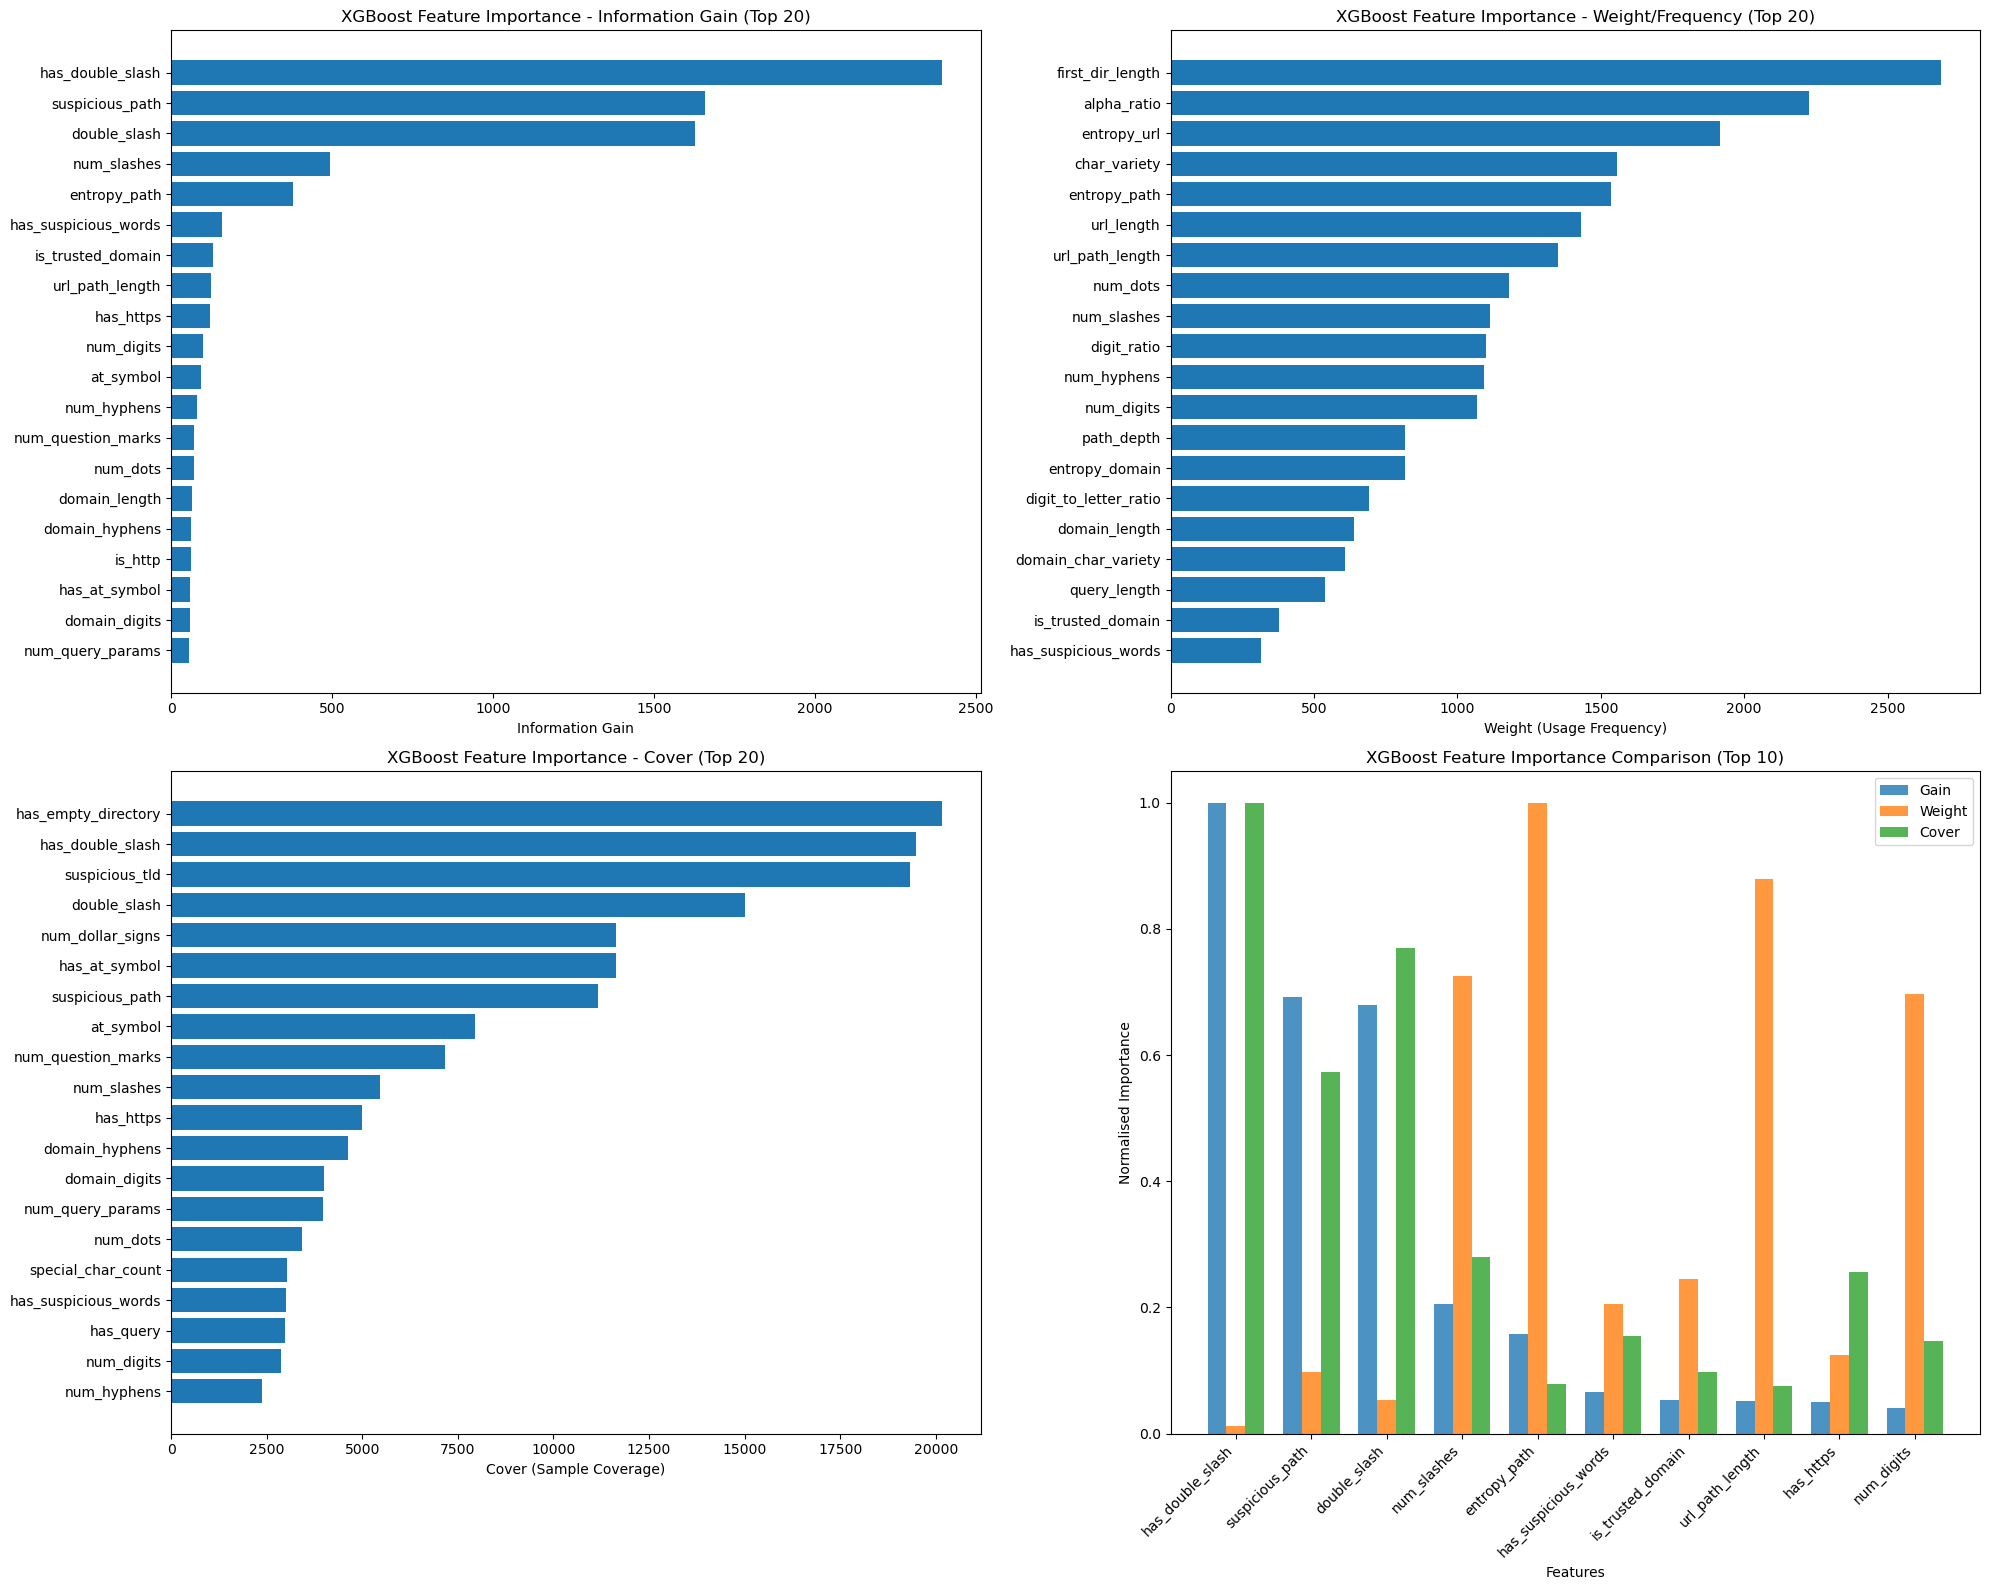

In [9]:
print("Feature importnace analysis:")

xgboost_model = trained_models['XGBoost']

importance_types = ['weight', 'gain', 'cover']
xgb_importances = {}

for imp_type in importance_types:
    importance_dict = xgboost_model.get_booster().get_score(importance_type=imp_type)
    xgb_importances[imp_type] = importance_dict

feature_importance_df = pd.DataFrame({
    'feature': X.columns,
    'weight': [xgb_importances['weight'].get(f, 0) for f in X.columns],
    'gain': [xgb_importances['gain'].get(f, 0) for f in X.columns],
    'cover': [xgb_importances['cover'].get(f, 0) for f in X.columns]
})

for imp_type in importance_types:
    total = feature_importance_df[imp_type].sum()
    if total > 0:
        feature_importance_df[f'{imp_type}_normalized'] = feature_importance_df[imp_type] / total
    else:
        feature_importance_df[f'{imp_type}_normalized'] = 0

feature_importance_df = feature_importance_df.sort_values('gain', ascending=False)

print(f"\nMost important features by information gain")
print(f"{'Rank':<4} {'Feature':<25} {'Gain':<12} {'Weight':<10} {'Cover':<10}")

for i, (_, row) in enumerate(feature_importance_df.iterrows()):
    print(f"{i+1:<4} {row['feature']:<25} {row['gain']:<12.4f} {row['weight']:<10.0f} {row['cover']:<10.4f}")

fig, axes = plt.subplots(2, 2, figsize=(20, 16))

# importance by gain
top_20_gain = feature_importance_df.head(20)
axes[0, 0].barh(range(len(top_20_gain)), top_20_gain['gain'])
axes[0, 0].set_yticks(range(len(top_20_gain)))
axes[0, 0].set_yticklabels(top_20_gain['feature'])
axes[0, 0].set_xlabel('Information Gain')
axes[0, 0].set_title('XGBoost Feature Importance - Information Gain (Top 20)')
axes[0, 0].invert_yaxis()

# importance by weight
top_20_weight = feature_importance_df.sort_values('weight', ascending=False).head(20)
axes[0, 1].barh(range(len(top_20_weight)), top_20_weight['weight'])
axes[0, 1].set_yticks(range(len(top_20_weight)))
axes[0, 1].set_yticklabels(top_20_weight['feature'])
axes[0, 1].set_xlabel('Weight (Usage Frequency)')
axes[0, 1].set_title('XGBoost Feature Importance - Weight/Frequency (Top 20)')
axes[0, 1].invert_yaxis()

# importance by cover
top_20_cover = feature_importance_df.sort_values('cover', ascending=False).head(20)
axes[1, 0].barh(range(len(top_20_cover)), top_20_cover['cover'])
axes[1, 0].set_yticks(range(len(top_20_cover)))
axes[1, 0].set_yticklabels(top_20_cover['feature'])
axes[1, 0].set_xlabel('Cover (Sample Coverage)')
axes[1, 0].set_title('XGBoost Feature Importance - Cover (Top 20)')
axes[1, 0].invert_yaxis()

top_10_features = feature_importance_df.head(10)
x_pos = np.arange(len(top_10_features))

gain_norm = top_10_features['gain'] / top_10_features['gain'].max()
weight_norm = top_10_features['weight'] / top_10_features['weight'].max()
cover_norm = top_10_features['cover'] / top_10_features['cover'].max()

width = 0.25
axes[1, 1].bar(x_pos - width, gain_norm, width, label='Gain', alpha=0.8)
axes[1, 1].bar(x_pos, weight_norm, width, label='Weight', alpha=0.8)
axes[1, 1].bar(x_pos + width, cover_norm, width, label='Cover', alpha=0.8)

axes[1, 1].set_xlabel('Features')
axes[1, 1].set_ylabel('Normalised Importance')
axes[1, 1].set_title('XGBoost Feature Importance Comparison (Top 10)')
axes[1, 1].set_xticks(x_pos)
axes[1, 1].set_xticklabels(top_10_features['feature'], rotation=45, ha='right')
axes[1, 1].legend()

plt.tight_layout()
plt.savefig('xgb_feature_importance_analysis.png', dpi=300, bbox_inches='tight')
plt.show()


### 2. Feature Contribution to False Positives


False positives analysis


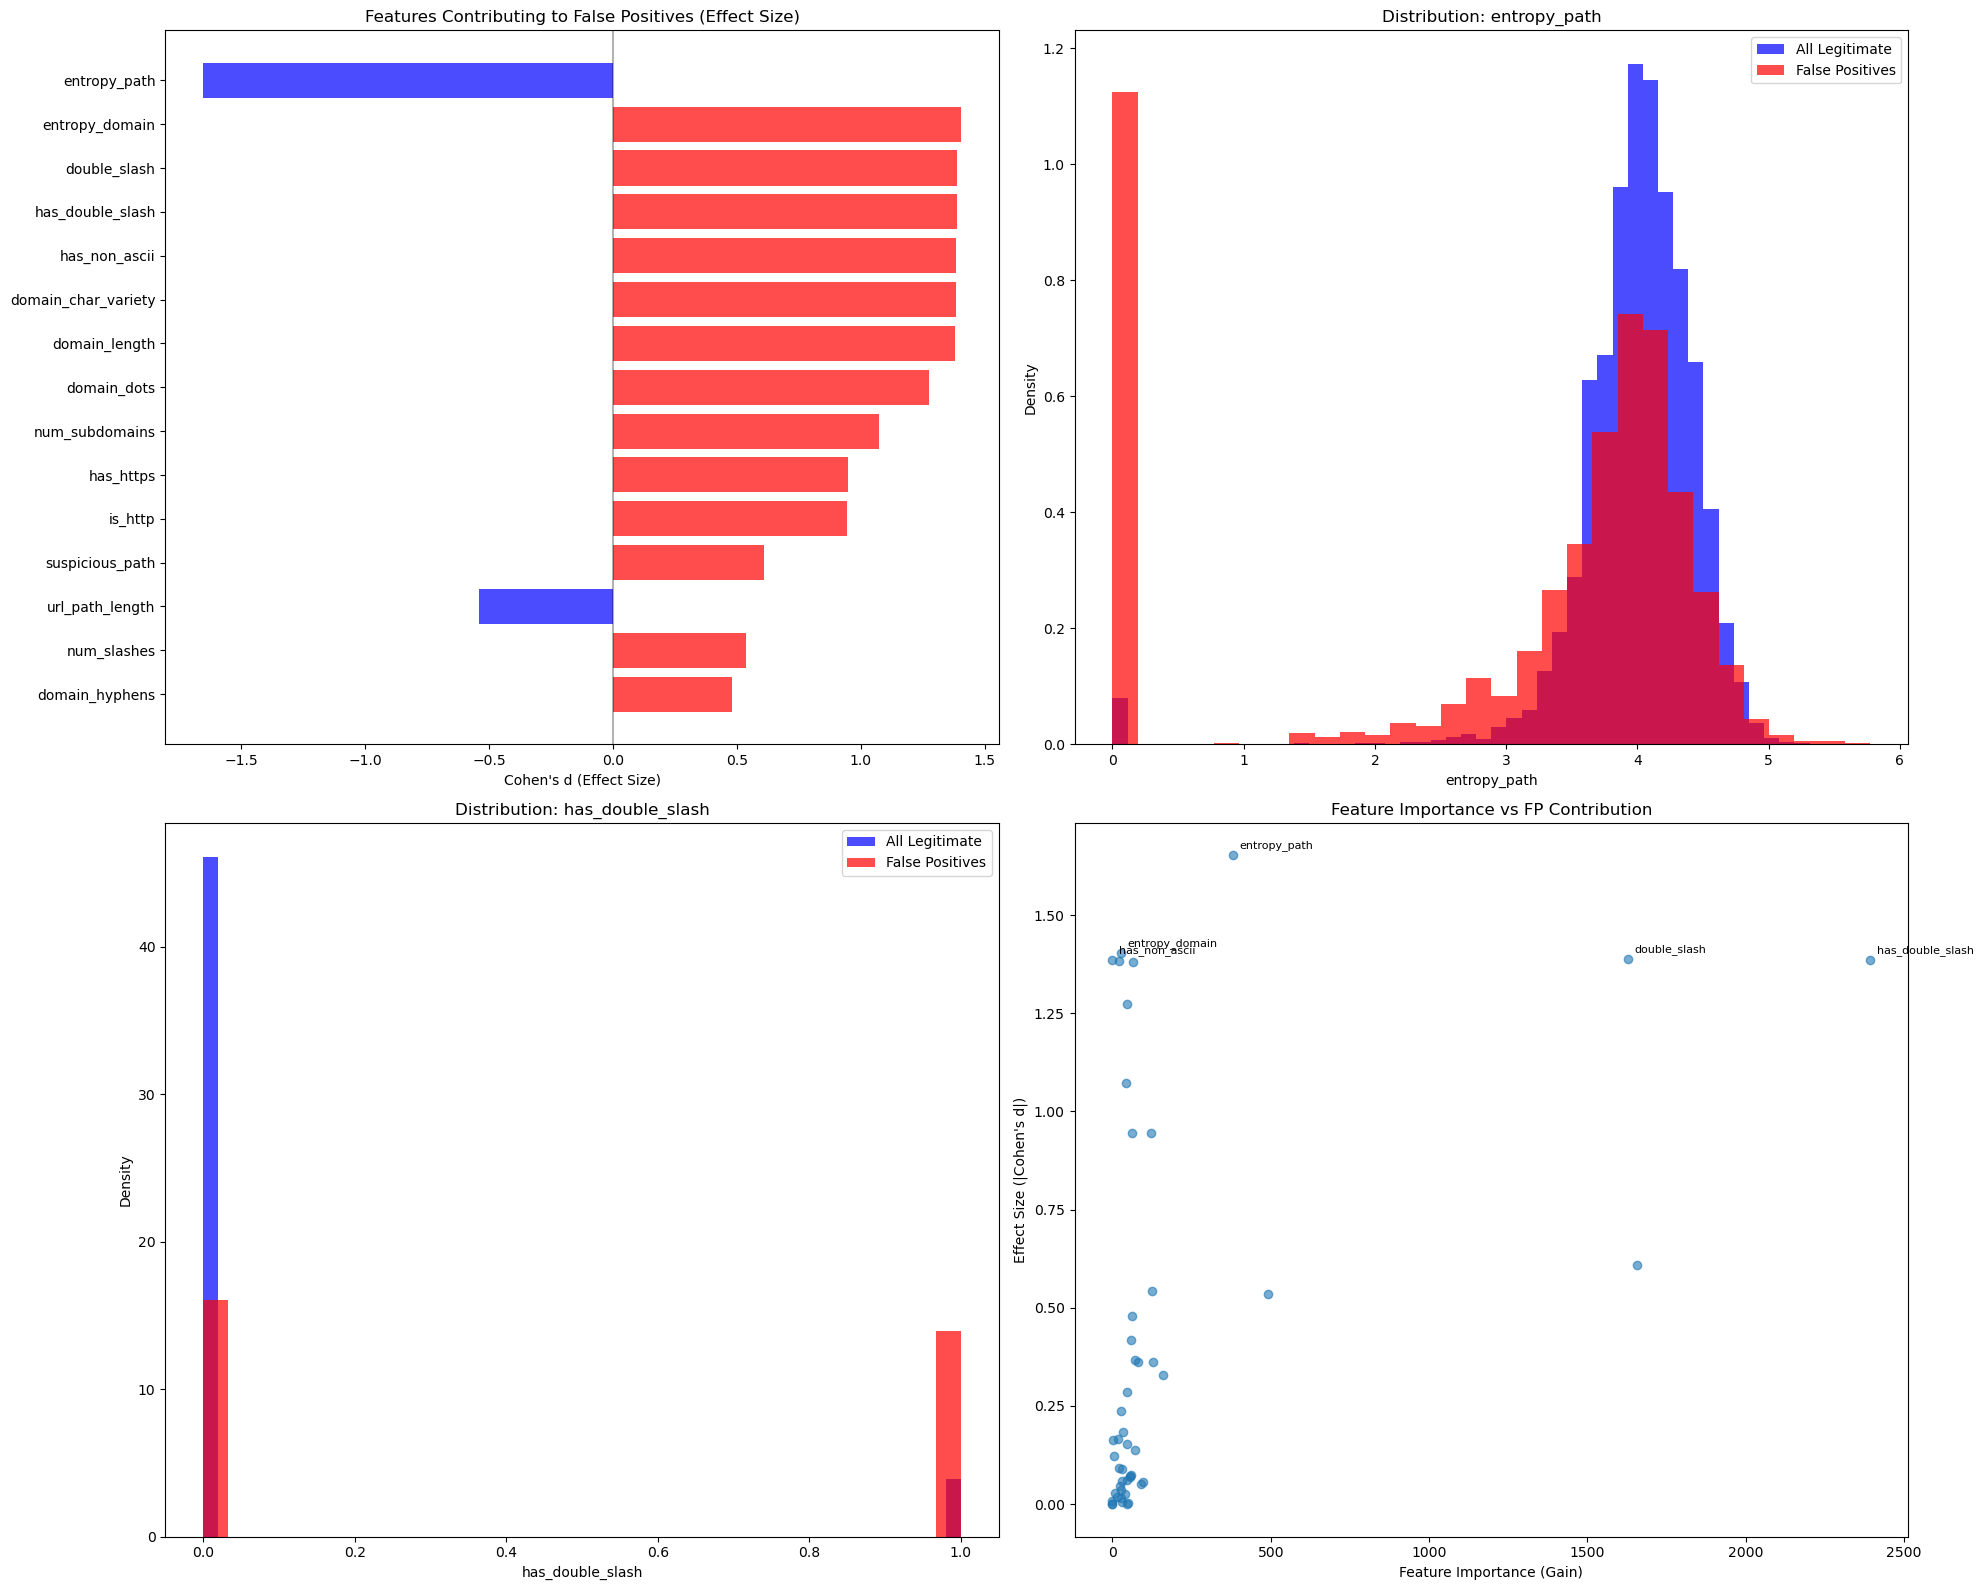

In [10]:

print("False positives analysis")

xgb_val_proba = xgboost_model.predict_proba(X_val)[:, 1] 
xgb_val_pred = (xgb_val_proba >= 0.5).astype(int) 

fp_mask = (y_val == 0) & (xgb_val_pred == 1)
fp_indices = np.where(fp_mask)[0]


if len(fp_indices) == 0:
    print("No false positives")
    # using a lower threshold to capture false positives for analysis
    xgb_val_pred_low = (xgb_val_proba >= 0.3).astype(int)
    fp_mask = (y_val == 0) & (xgb_val_pred_low == 1)
    fp_indices = np.where(fp_mask)[0]

if len(fp_indices) > 0:
    X_fp = X_val.iloc[fp_indices] 
    X_legitimate = X_val.iloc[y_val == 0] 
        
    fp_stats = []
    
    for feature in X.columns:
        fp_mean = X_fp[feature].mean()
        legit_mean = X_legitimate[feature].mean()
        fp_std = X_fp[feature].std()
        legit_std = X_legitimate[feature].std()
        
        mean_diff = fp_mean - legit_mean
        relative_diff = (mean_diff / legit_mean * 100) if legit_mean != 0 else 0
        
        pooled_std = np.sqrt(((len(X_fp) - 1) * fp_std**2 + (len(X_legitimate) - 1) * legit_std**2) / 
                           (len(X_fp) + len(X_legitimate) - 2))
        cohens_d = mean_diff / pooled_std if pooled_std > 0 else 0
        
        fp_stats.append({
            'feature': feature,
            'fp_mean': fp_mean,
            'legit_mean': legit_mean,
            'mean_diff': mean_diff,
            'relative_diff': relative_diff,
            'cohens_d': cohens_d,
            'fp_std': fp_std,
            'legit_std': legit_std
        })
    
    fp_analysis = pd.DataFrame(fp_stats)
    fp_analysis['abs_cohens_d'] = fp_analysis['cohens_d'].abs()
    fp_analysis = fp_analysis.sort_values('abs_cohens_d', ascending=False)
    
    fig, axes = plt.subplots(2, 2, figsize=(20, 16))
    
    top_15_effect = fp_analysis.head(15)
    colors = ['red' if x > 0 else 'blue' for x in top_15_effect['cohens_d']]
    
    axes[0, 0].barh(range(len(top_15_effect)), top_15_effect['cohens_d'], color=colors, alpha=0.7)
    axes[0, 0].set_yticks(range(len(top_15_effect)))
    axes[0, 0].set_yticklabels(top_15_effect['feature'])
    axes[0, 0].set_xlabel("Cohen's d (Effect Size)")
    axes[0, 0].set_title('Features Contributing to False Positives (Effect Size)')
    axes[0, 0].axvline(x=0, color='black', linestyle='-', alpha=0.3)
    axes[0, 0].invert_yaxis()
    
    top_5_features = fp_analysis.head(5)['feature'].values
    
    for i, feature in enumerate(top_5_features[:4]):  
        row = i // 2
        col = 1 if i % 2 == 0 else 0
        if row == 0 and col == 1:
            ax = axes[0, 1]
        elif row == 1 and col == 0:
            ax = axes[1, 0]
        else:
            continue
            
        ax.hist(X_legitimate[feature], bins=50, alpha=0.7, label='All Legitimate', density=True, color='blue')
        ax.hist(X_fp[feature], bins=30, alpha=0.7, label='False Positives', density=True, color='red')
        ax.set_xlabel(feature)
        ax.set_ylabel('Density')
        ax.set_title(f'Distribution: {feature}')
        ax.legend()
    
    
    fp_importance = fp_analysis.merge(
        feature_importance_df[['feature', 'gain', 'weight']], 
        on='feature', how='left'
    )
    
    axes[1, 1].scatter(fp_importance['gain'], fp_importance['abs_cohens_d'], alpha=0.6)
    axes[1, 1].set_xlabel('Feature Importance (Gain)')
    axes[1, 1].set_ylabel('Effect Size (|Cohen\'s d|)')
    axes[1, 1].set_title('Feature Importance vs FP Contribution')
    
    top_contributors = fp_importance.nlargest(5, 'abs_cohens_d')
    for _, row in top_contributors.iterrows():
        axes[1, 1].annotate(row['feature'], (row['gain'], row['abs_cohens_d']), 
                           xytext=(5, 5), textcoords='offset points', fontsize=8)
    
    plt.tight_layout()
    plt.savefig('xgb_fp_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    

### 3. Partial Dependence Plots (PDPs) for False Positives

PDPs for FPs


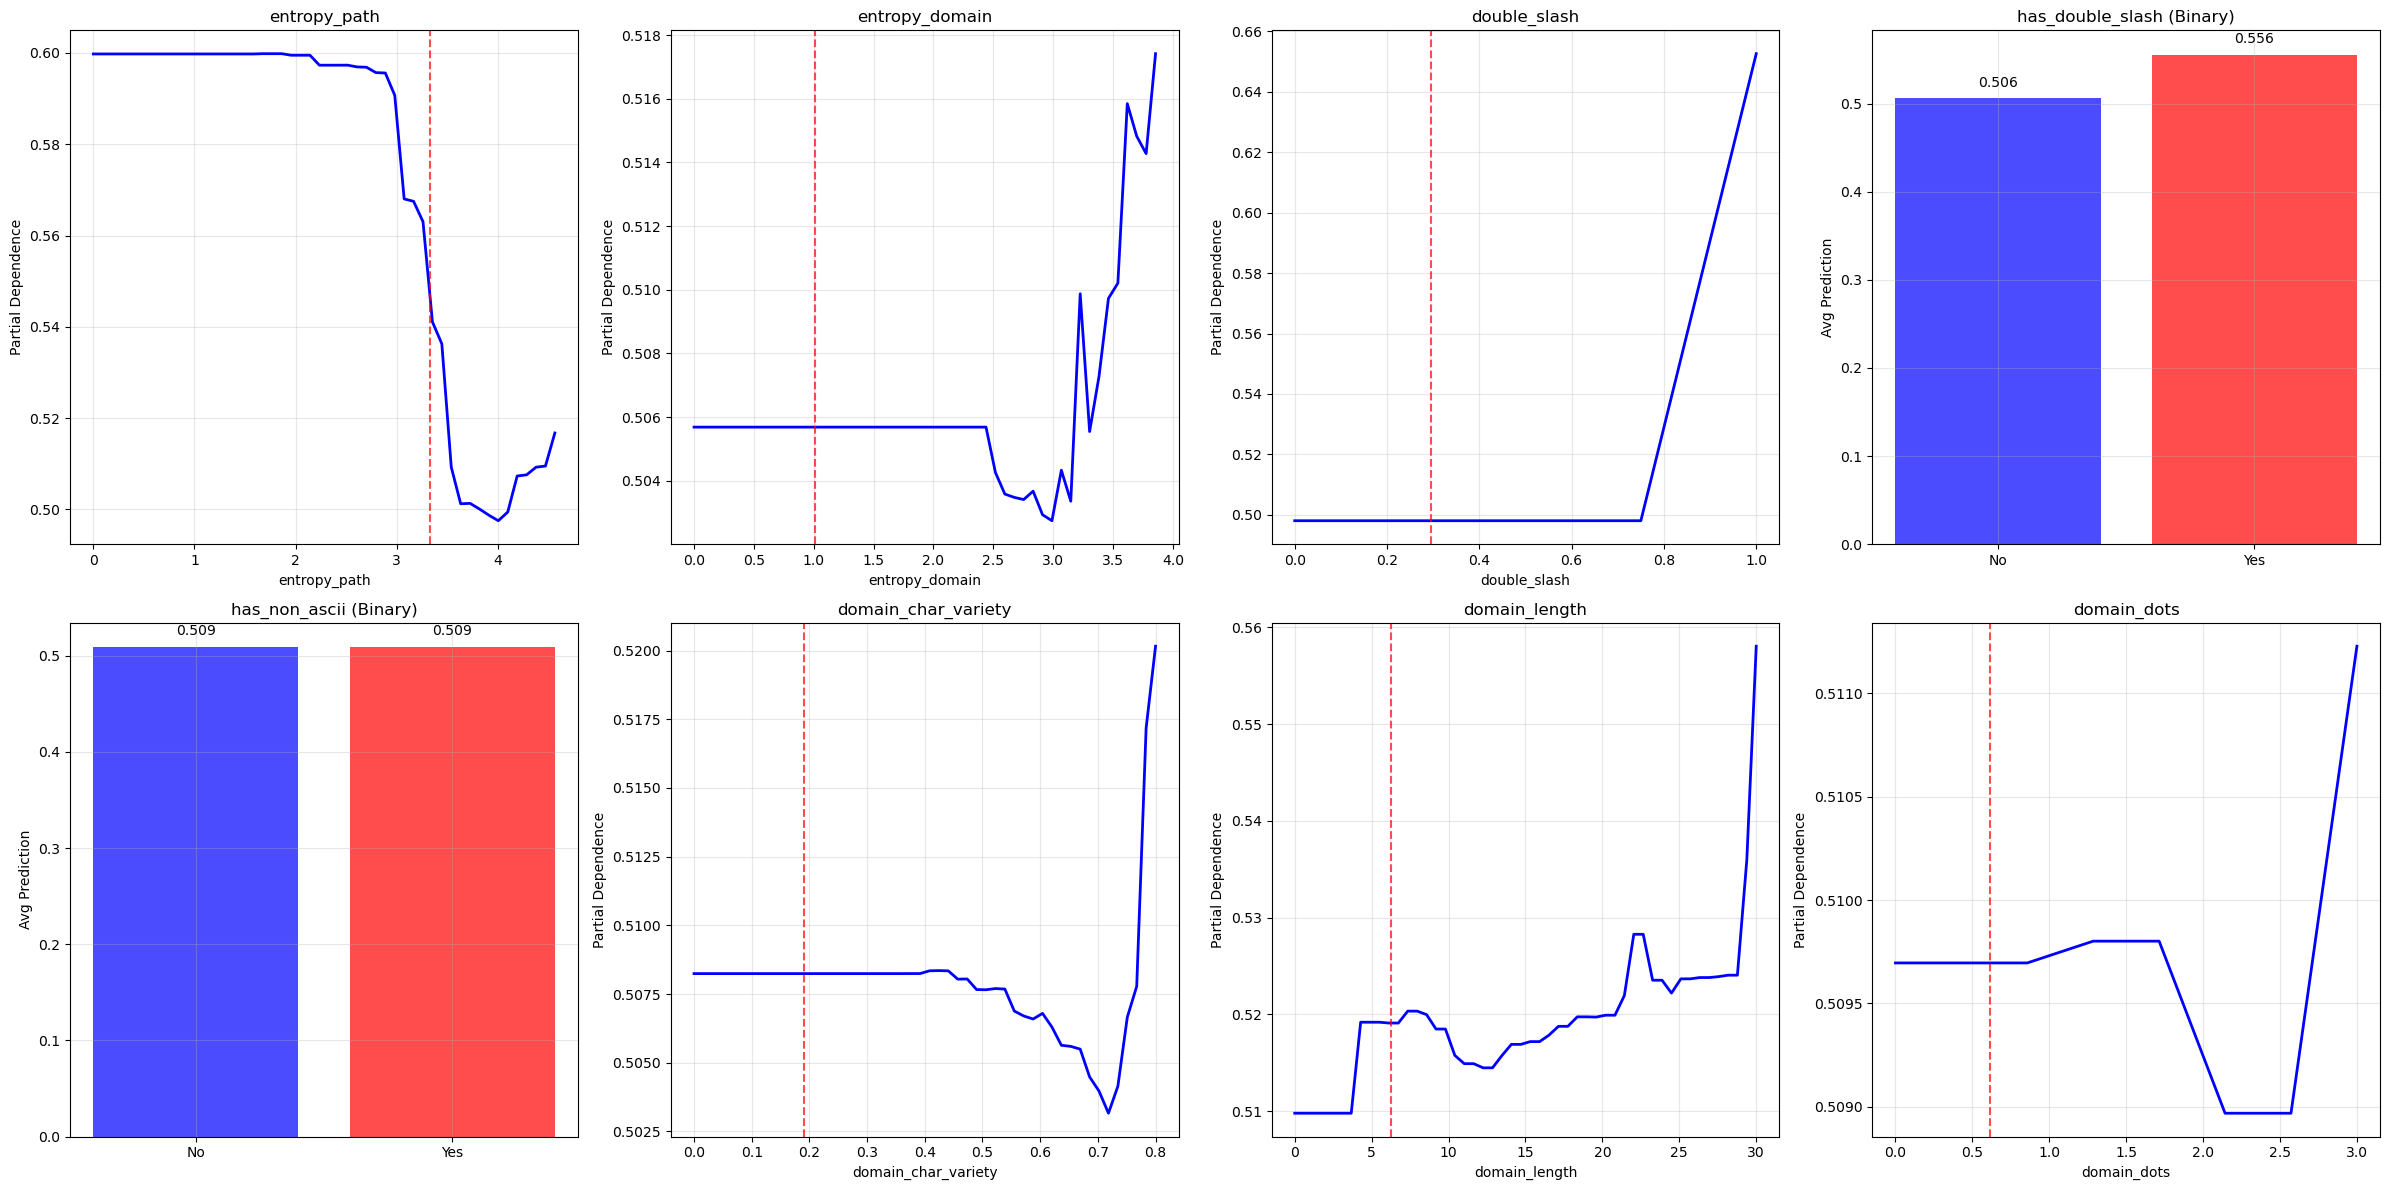

In [11]:
print("PDPs for FPs")

if 'fp_analysis' in locals() and len(fp_analysis) > 0: 
    top_fp_features = fp_analysis.head(8)['feature'].tolist() # get most important features for FPs if possible
else:
    top_fp_features = feature_importance_df.head(8)['feature'].tolist() # else get model's most important

# create samples
sample_size = min(3000, len(X_val))
sample_indices = np.random.choice(len(X_val), sample_size, replace=False)
X_sample = X_val.iloc[sample_indices]

fig, axes = plt.subplots(2, 4, figsize=(24, 12))
axes = axes.ravel()

for i, feature in enumerate(top_fp_features):
    try:
        feature_values = X_sample[feature]
        unique_values = feature_values.unique()
        
        if len(unique_values) < 2:
            axes[i].text(0.5, 0.5, f'{feature}\n(No variation)', 
                        ha='center', va='center', transform=axes[i].transAxes)
            axes[i].set_title(f'{feature} (Constant)')
            continue
        
        # for binary features 
        if len(unique_values) == 2 and set(unique_values).issubset({0, 1}):
            pd_values = []
            for val in [0, 1]:
                X_modified = X_sample.copy()
                X_modified[feature] = val
                pred_proba = xgboost_model.predict_proba(X_modified)[:, 1]
                pd_values.append(pred_proba.mean())
            
            axes[i].bar(['No', 'Yes'], pd_values, color=['blue', 'red'], alpha=0.7)
            axes[i].set_ylabel('Avg Prediction')
            axes[i].set_title(f'{feature} (Binary)')
            
            for j, val in enumerate(pd_values):
                axes[i].text(j, val + 0.01, f'{val:.3f}', ha='center', va='bottom')
        
        else:
            # for continuous features 
            feature_idx = list(X.columns).index(feature)
            pd_result = partial_dependence(
                xgboost_model, X_sample, features=[feature_idx],
                kind='average', grid_resolution=min(50, len(unique_values))
            )
            
            axes[i].plot(pd_result['grid_values'][0], pd_result['average'][0], 
                        linewidth=2, color='blue')
            axes[i].set_xlabel(feature)
            axes[i].set_ylabel('Partial Dependence')
            axes[i].set_title(f'{feature}')
            
            feature_mean = X_sample[feature].mean()
            axes[i].axvline(feature_mean, color='red', linestyle='--', alpha=0.7)
            
        axes[i].grid(True, alpha=0.3)
        
    except Exception as e:
        axes[i].text(0.5, 0.5, f'Error:\n{feature}', 
                    ha='center', va='center', transform=axes[i].transAxes)

plt.tight_layout()
plt.savefig('xgb_pdp_FP_analysis.png', dpi=300, bbox_inches='tight')
plt.show()


### 4. False Negative Analysis


False negatives analysis


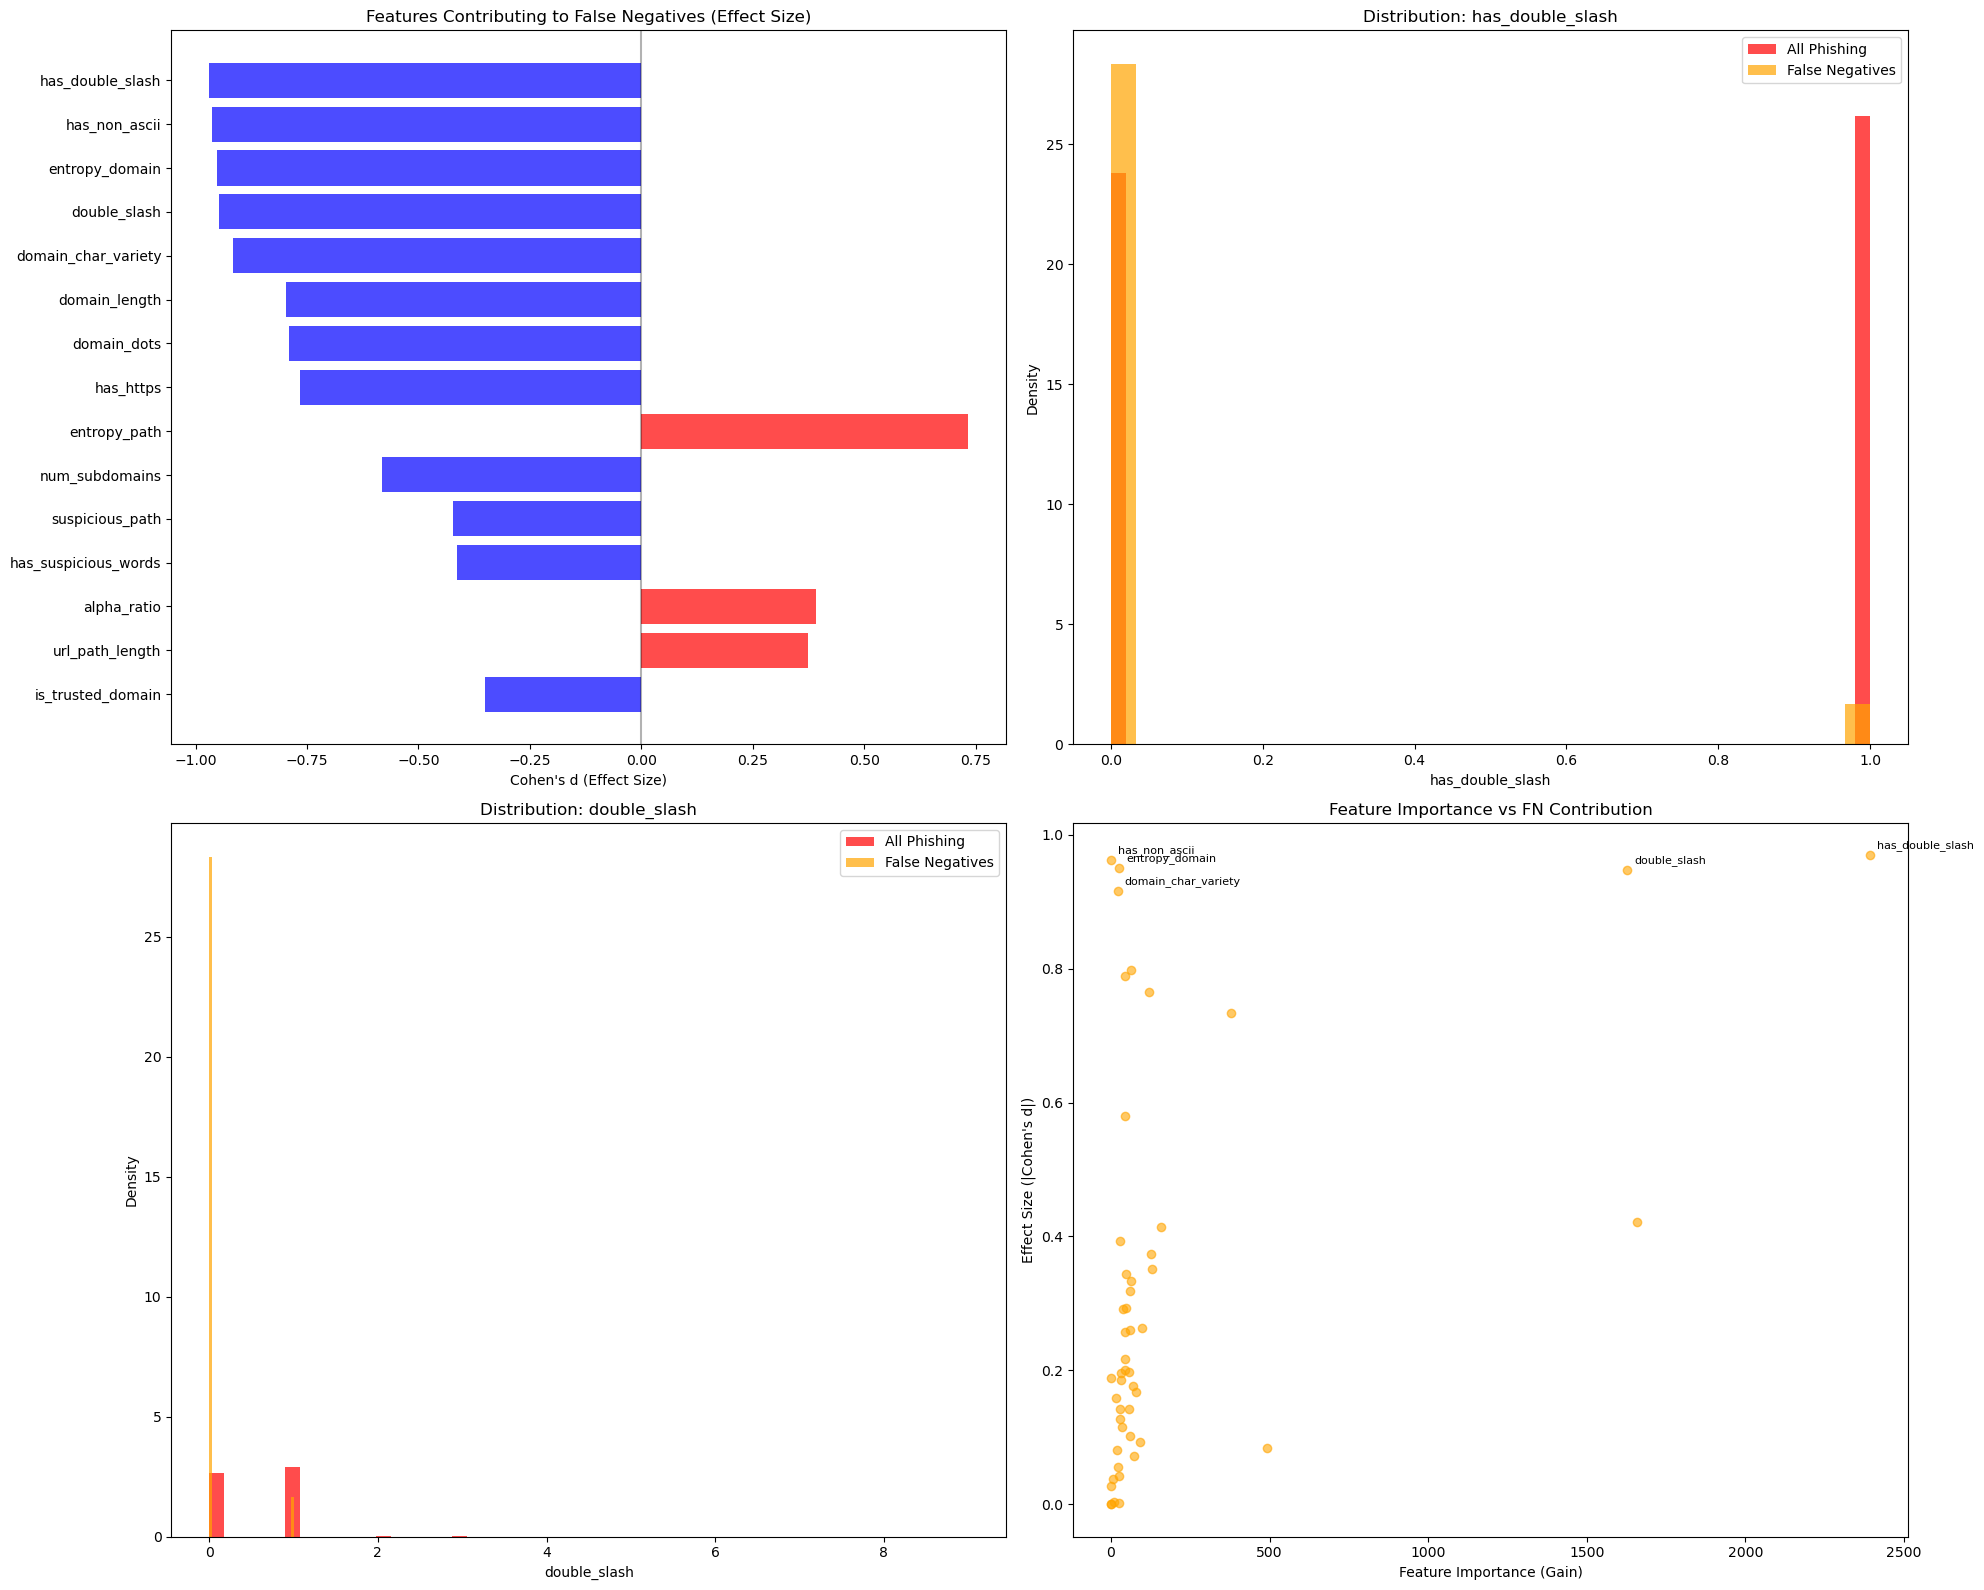

In [12]:
print("False negatives analysis")

xgb_val_proba = xgboost_model.predict_proba(X_val)[:, 1] 
xgb_val_pred = (xgb_val_proba >= 0.5).astype(int) 

fn_mask = (y_val == 1) & (xgb_val_pred == 0)
fn_indices = np.where(fn_mask)[0]

if len(fn_indices) == 0:
    print("No false negatives")
    # using a higher threshold to capture false negatives for analysis
    xgb_val_pred_high = (xgb_val_proba >= 0.7).astype(int)
    fn_mask = (y_val == 1) & (xgb_val_pred_high == 0)
    fn_indices = np.where(fn_mask)[0]

if len(fn_indices) > 0:
    X_fn = X_val.iloc[fn_indices] 
    X_phishing = X_val.iloc[y_val == 1] 
        
    fn_stats = []
    
    for feature in X.columns:
        fn_mean = X_fn[feature].mean()
        phishing_mean = X_phishing[feature].mean()
        fn_std = X_fn[feature].std()
        phishing_std = X_phishing[feature].std()
        
        mean_diff = fn_mean - phishing_mean
        relative_diff = (mean_diff / phishing_mean * 100) if phishing_mean != 0 else 0
        
        pooled_std = np.sqrt(((len(X_fn) - 1) * fn_std**2 + (len(X_phishing) - 1) * phishing_std**2) / 
                           (len(X_fn) + len(X_phishing) - 2))
        cohens_d = mean_diff / pooled_std if pooled_std > 0 else 0
        
        fn_stats.append({
            'feature': feature,
            'fn_mean': fn_mean,
            'phishing_mean': phishing_mean,
            'mean_diff': mean_diff,
            'relative_diff': relative_diff,
            'cohens_d': cohens_d,
            'fn_std': fn_std,
            'phishing_std': phishing_std
        })
    
    fn_analysis = pd.DataFrame(fn_stats)
    fn_analysis['abs_cohens_d'] = fn_analysis['cohens_d'].abs()
    fn_analysis = fn_analysis.sort_values('abs_cohens_d', ascending=False)
    
    fig, axes = plt.subplots(2, 2, figsize=(20, 16))
    
    top_15_effect = fn_analysis.head(15)
    colors = ['red' if x > 0 else 'blue' for x in top_15_effect['cohens_d']]
    
    axes[0, 0].barh(range(len(top_15_effect)), top_15_effect['cohens_d'], color=colors, alpha=0.7)
    axes[0, 0].set_yticks(range(len(top_15_effect)))
    axes[0, 0].set_yticklabels(top_15_effect['feature'])
    axes[0, 0].set_xlabel("Cohen's d (Effect Size)")
    axes[0, 0].set_title('Features Contributing to False Negatives (Effect Size)')
    axes[0, 0].axvline(x=0, color='black', linestyle='-', alpha=0.3)
    axes[0, 0].invert_yaxis()
    
    top_5_features = fn_analysis.head(5)['feature'].values
    
    for i, feature in enumerate(top_5_features[:4]):  
        row = i // 2
        col = 1 if i % 2 == 0 else 0
        if row == 0 and col == 1:
            ax = axes[0, 1]
        elif row == 1 and col == 0:
            ax = axes[1, 0]
        else:
            continue
            
        ax.hist(X_phishing[feature], bins=50, alpha=0.7, label='All Phishing', density=True, color='red')
        ax.hist(X_fn[feature], bins=30, alpha=0.7, label='False Negatives', density=True, color='orange')
        ax.set_xlabel(feature)
        ax.set_ylabel('Density')
        ax.set_title(f'Distribution: {feature}')
        ax.legend()
    
    fn_importance = fn_analysis.merge(
        feature_importance_df[['feature', 'gain', 'weight']], 
        on='feature', how='left'
    )
    
    axes[1, 1].scatter(fn_importance['gain'], fn_importance['abs_cohens_d'], alpha=0.6, color='orange')
    axes[1, 1].set_xlabel('Feature Importance (Gain)')
    axes[1, 1].set_ylabel('Effect Size (|Cohen\'s d|)')
    axes[1, 1].set_title('Feature Importance vs FN Contribution')
    
    top_contributors = fn_importance.nlargest(5, 'abs_cohens_d')
    for _, row in top_contributors.iterrows():
        axes[1, 1].annotate(row['feature'], (row['gain'], row['abs_cohens_d']), 
                           xytext=(5, 5), textcoords='offset points', fontsize=8)
    
    plt.tight_layout()
    plt.savefig('xgb_fn_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()

### 5. Partial Dependence Plots (PDPs) for False Negatives


PDPs for FNs


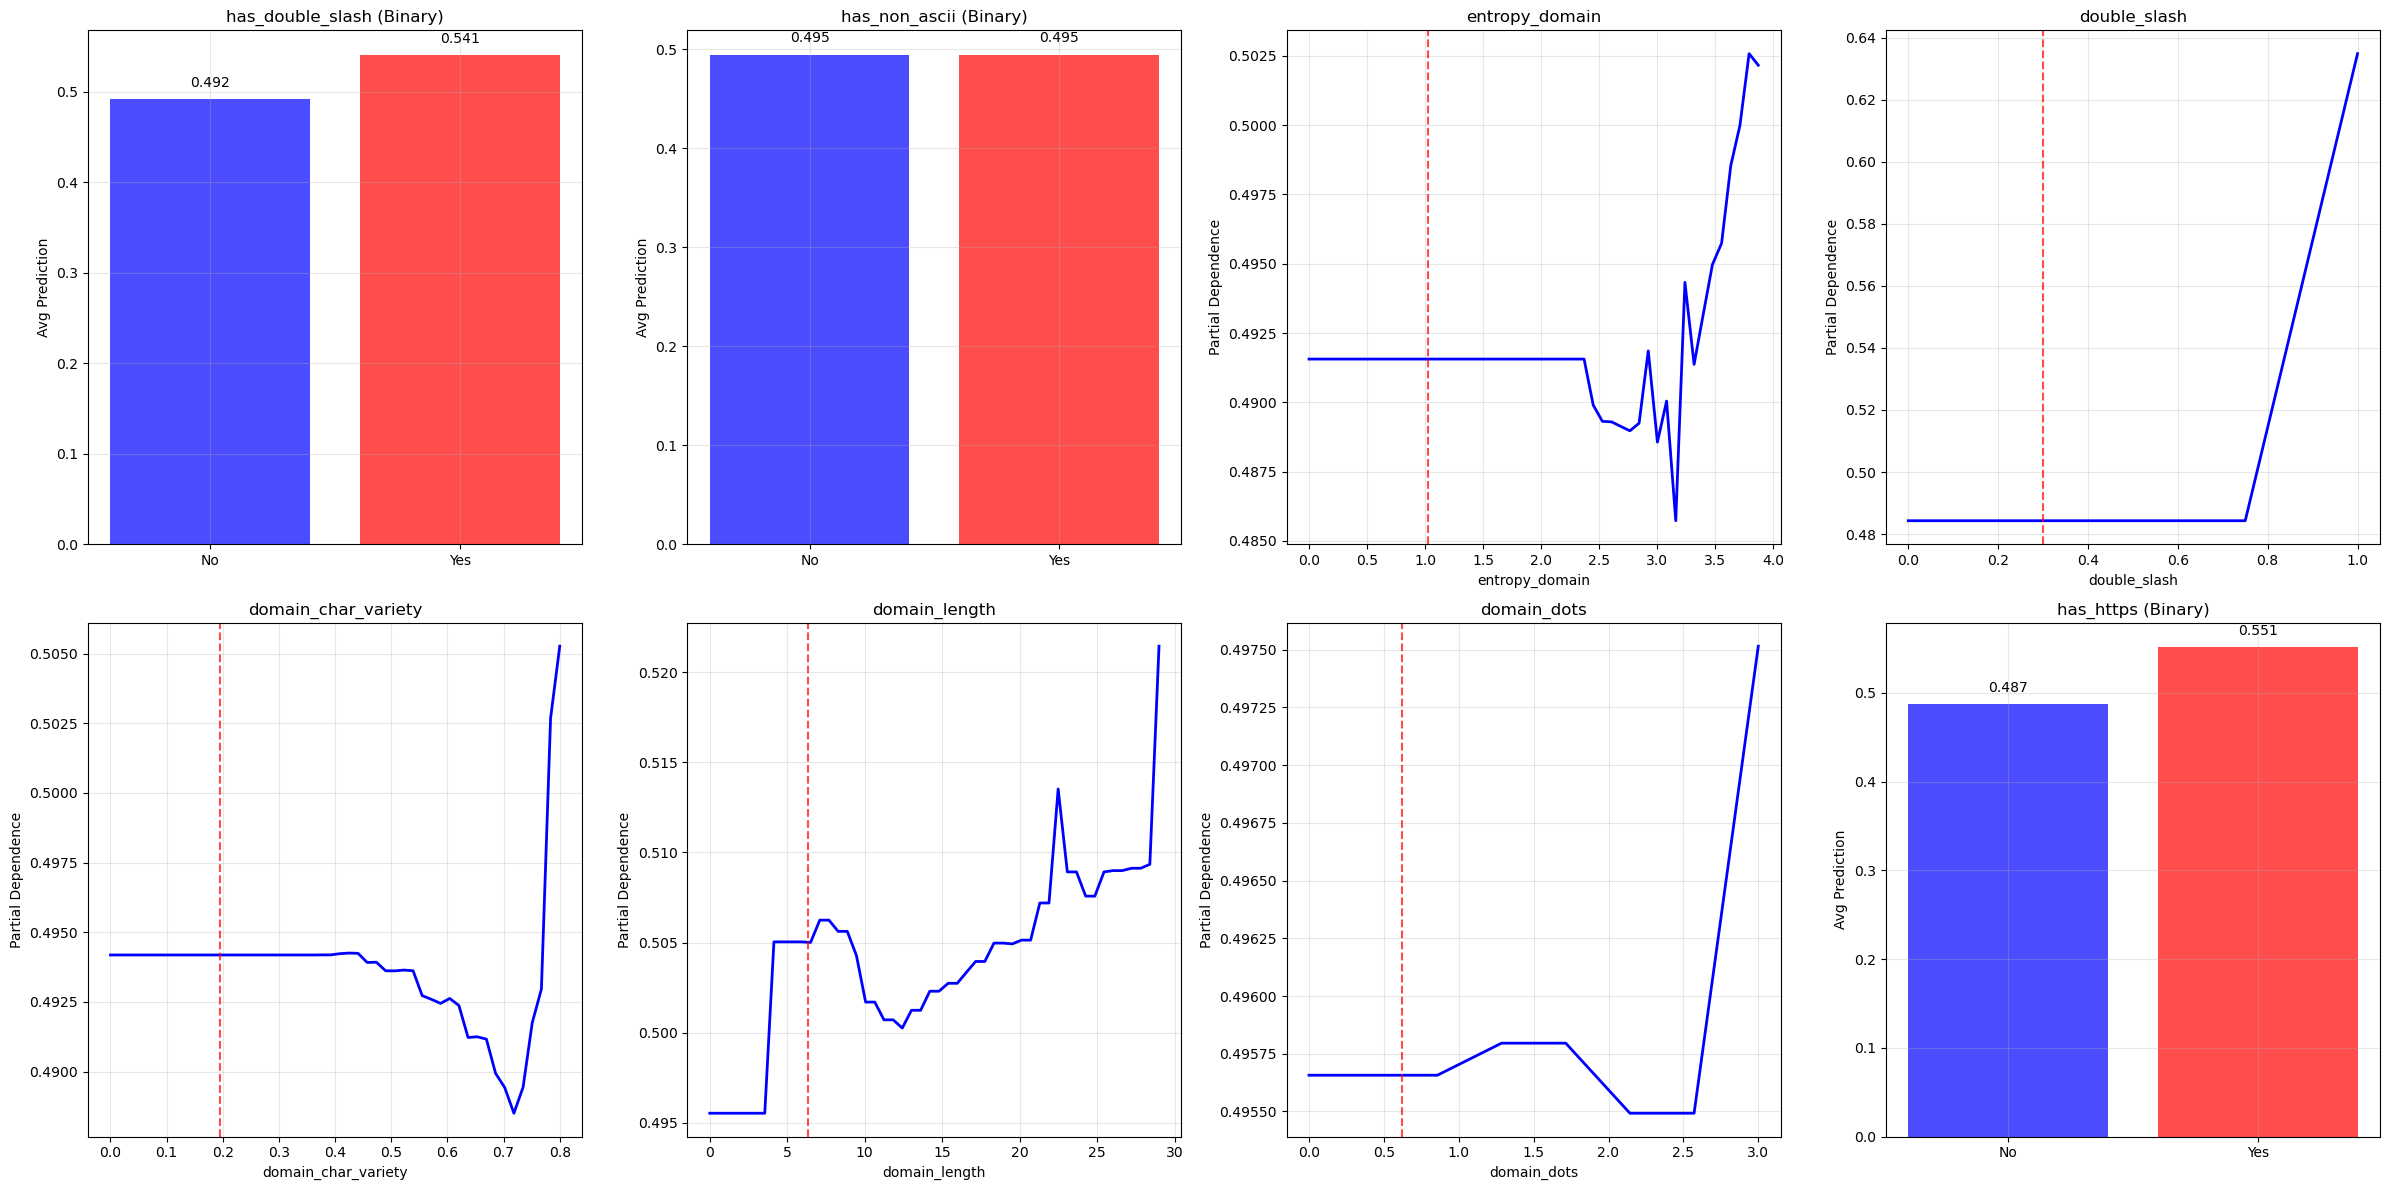

In [13]:
print("PDPs for FNs")

if 'fn_analysis' in locals() and len(fn_analysis) > 0:
    top_fn_features = fn_analysis.head(8)['feature'].tolist() # get most important features for FNs if possible
else:
    top_fn_features = feature_importance_df.head(8)['feature'].tolist() # else get model's most important

# create samples
sample_size = min(3000, len(X_val))
sample_indices = np.random.choice(len(X_val), sample_size, replace=False)
X_sample = X_val.iloc[sample_indices]

fig, axes = plt.subplots(2, 4, figsize=(24, 12))
axes = axes.ravel()

for i, feature in enumerate(top_fn_features):
    try:
        feature_values = X_sample[feature]
        unique_values = feature_values.unique()
        
        if len(unique_values) < 2:
            axes[i].text(0.5, 0.5, f'{feature}\n(No variation)', 
                        ha='center', va='center', transform=axes[i].transAxes)
            axes[i].set_title(f'{feature} (Constant)')
            continue
        
        # for binary features 
        if len(unique_values) == 2 and set(unique_values).issubset({0, 1}):
            pd_values = []
            for val in [0, 1]:
                X_modified = X_sample.copy()
                X_modified[feature] = val
                pred_proba = xgboost_model.predict_proba(X_modified)[:, 1]
                pd_values.append(pred_proba.mean())
            
            axes[i].bar(['No', 'Yes'], pd_values, color=['blue', 'red'], alpha=0.7)
            axes[i].set_ylabel('Avg Prediction')
            axes[i].set_title(f'{feature} (Binary)')
            
            for j, val in enumerate(pd_values):
                axes[i].text(j, val + 0.01, f'{val:.3f}', ha='center', va='bottom')
        
        else:
            # for continuous features 
            feature_idx = list(X.columns).index(feature)
            pd_result = partial_dependence(
                xgboost_model, X_sample, features=[feature_idx],
                kind='average', grid_resolution=min(50, len(unique_values))
            )
            
            axes[i].plot(pd_result['grid_values'][0], pd_result['average'][0], 
                        linewidth=2, color='blue')
            axes[i].set_xlabel(feature)
            axes[i].set_ylabel('Partial Dependence')
            axes[i].set_title(f'{feature}')
            
            feature_mean = X_sample[feature].mean()
            axes[i].axvline(feature_mean, color='red', linestyle='--', alpha=0.7)
            
        axes[i].grid(True, alpha=0.3)
        
    except Exception as e:
        axes[i].text(0.5, 0.5, f'Error:\n{feature}', 
                    ha='center', va='center', transform=axes[i].transAxes)

plt.tight_layout()
plt.savefig('xgb_pdp_FN_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

### 6. SHAP Analysis for False Positives


SHAP for FPs


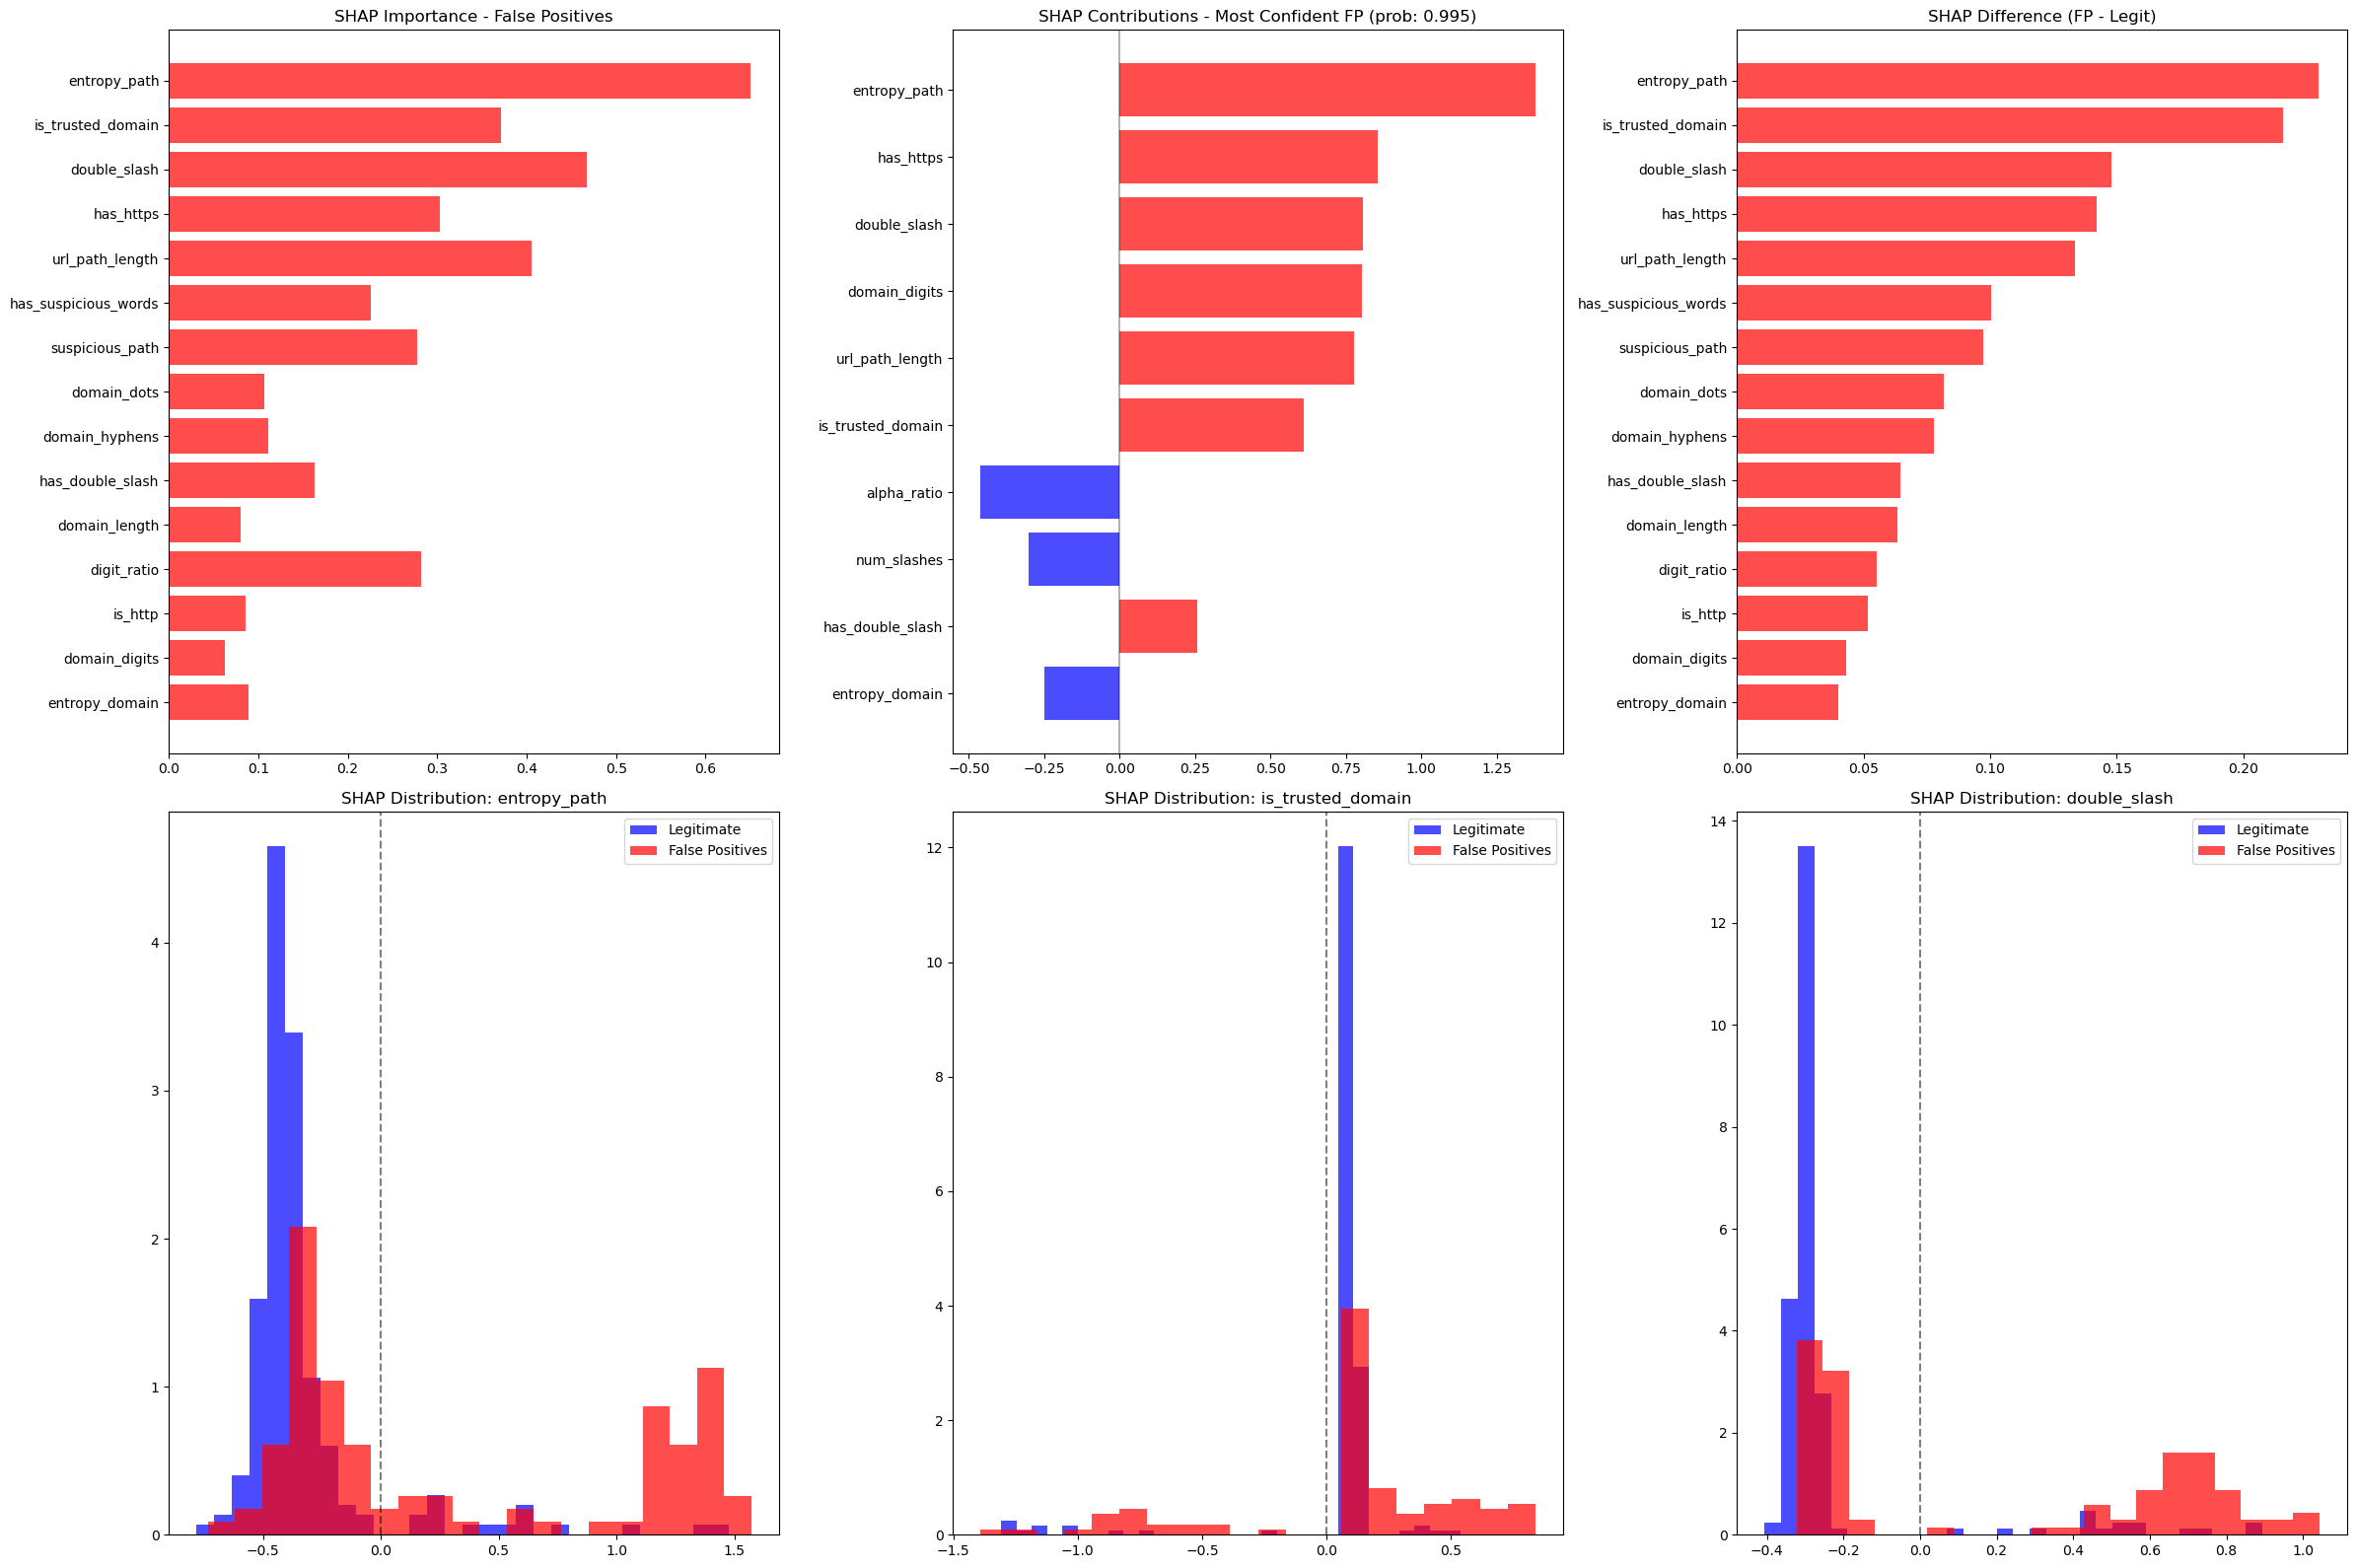

In [14]:
print("SHAP for FPs")

explainer = shap.TreeExplainer(xgboost_model)
shap_available = True
shap_available = False

if len(fp_indices) > 0: #there are FPs
    # sample for analysis
    max_fp_samples = min(100, len(fp_indices))
    fp_sample_indices = np.random.choice(fp_indices, max_fp_samples, replace=False)
    X_fp_sample = X_val.iloc[fp_sample_indices]
    
    legit_indices = np.where(y_val == 0)[0]
    max_legit_samples = min(200, len(legit_indices))
    legit_sample_indices = np.random.choice(legit_indices, max_legit_samples, replace=False)
    X_legit_sample = X_val.iloc[legit_sample_indices]
    
    shap_values_fp = explainer.shap_values(X_fp_sample)
    shap_values_legit = explainer.shap_values(X_legit_sample)
    
    mean_shap_fp = np.abs(shap_values_fp).mean(axis=0)
    mean_shap_legit = np.abs(shap_values_legit).mean(axis=0)
    
    shap_analysis = pd.DataFrame({
        'feature': X.columns,
        'shap_fp': mean_shap_fp,
        'shap_legit': mean_shap_legit,
        'shap_diff': mean_shap_fp - mean_shap_legit,
        'mean_effect_fp': shap_values_fp.mean(axis=0)
    }).sort_values('shap_diff', ascending=False)
    
    fig, axes = plt.subplots(2, 3, figsize=(24, 16))
    
    # SHAP importance graph
    top_15 = shap_analysis.head(15)
    axes[0, 0].barh(range(len(top_15)), top_15['shap_fp'], color='red', alpha=0.7)
    axes[0, 0].set_yticks(range(len(top_15)))
    axes[0, 0].set_yticklabels(top_15['feature'])
    axes[0, 0].set_title('SHAP Importance - False Positives')
    axes[0, 0].invert_yaxis()
    
    # SHAP contributions for FPs
    fp_probabilities = xgb_val_proba[fp_sample_indices]
    most_confident_idx = np.argmax(fp_probabilities)
    most_confident_prob = fp_probabilities[most_confident_idx]
    
    case_shap = shap_values_fp[most_confident_idx]
    case_features = pd.DataFrame({
        'feature': X.columns,
        'shap_value': case_shap
    }).sort_values('shap_value', key=abs, ascending=False).head(10)
    
    colors = ['red' if x > 0 else 'blue' for x in case_features['shap_value']]
    axes[0, 1].barh(range(len(case_features)), case_features['shap_value'], color=colors, alpha=0.7)
    axes[0, 1].set_yticks(range(len(case_features)))
    axes[0, 1].set_yticklabels(case_features['feature'])
    axes[0, 1].set_title(f'SHAP Contributions - Most Confident FP (prob: {most_confident_prob:.3f})')
    axes[0, 1].axvline(0, color='black', linestyle='-', alpha=0.3)
    axes[0, 1].invert_yaxis()
    
    # SHAP difference graph
    axes[0, 2].barh(range(len(top_15)), top_15['shap_diff'], 
                   color=['red' if x > 0 else 'blue' for x in top_15['shap_diff']], alpha=0.7)
    axes[0, 2].set_yticks(range(len(top_15)))
    axes[0, 2].set_yticklabels(top_15['feature'])
    axes[0, 2].set_title('SHAP Difference (FP - Legit)')
    axes[0, 2].axvline(0, color='black', linestyle='-', alpha=0.3)
    axes[0, 2].invert_yaxis()
    
    # SHAP distributions for top 3 features
    for i, feature in enumerate(top_15.head(3)['feature']):
        feature_idx = list(X.columns).index(feature)
        fp_shap = shap_values_fp[:, feature_idx]
        legit_shap = shap_values_legit[:, feature_idx]
        
        ax = axes[1, i]
        ax.hist(legit_shap, bins=30, alpha=0.7, label='Legitimate', density=True, color='blue')
        ax.hist(fp_shap, bins=20, alpha=0.7, label='False Positives', density=True, color='red')
        ax.axvline(0, color='black', linestyle='--', alpha=0.5)
        ax.set_title(f'SHAP Distribution: {feature}')
        ax.legend()
    
    plt.tight_layout()
    plt.savefig('xgb_shap_fp_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()
    

else:
    print("no fPs")



### 7. SHAP Analysis for False Negatives


SHAP for FNs


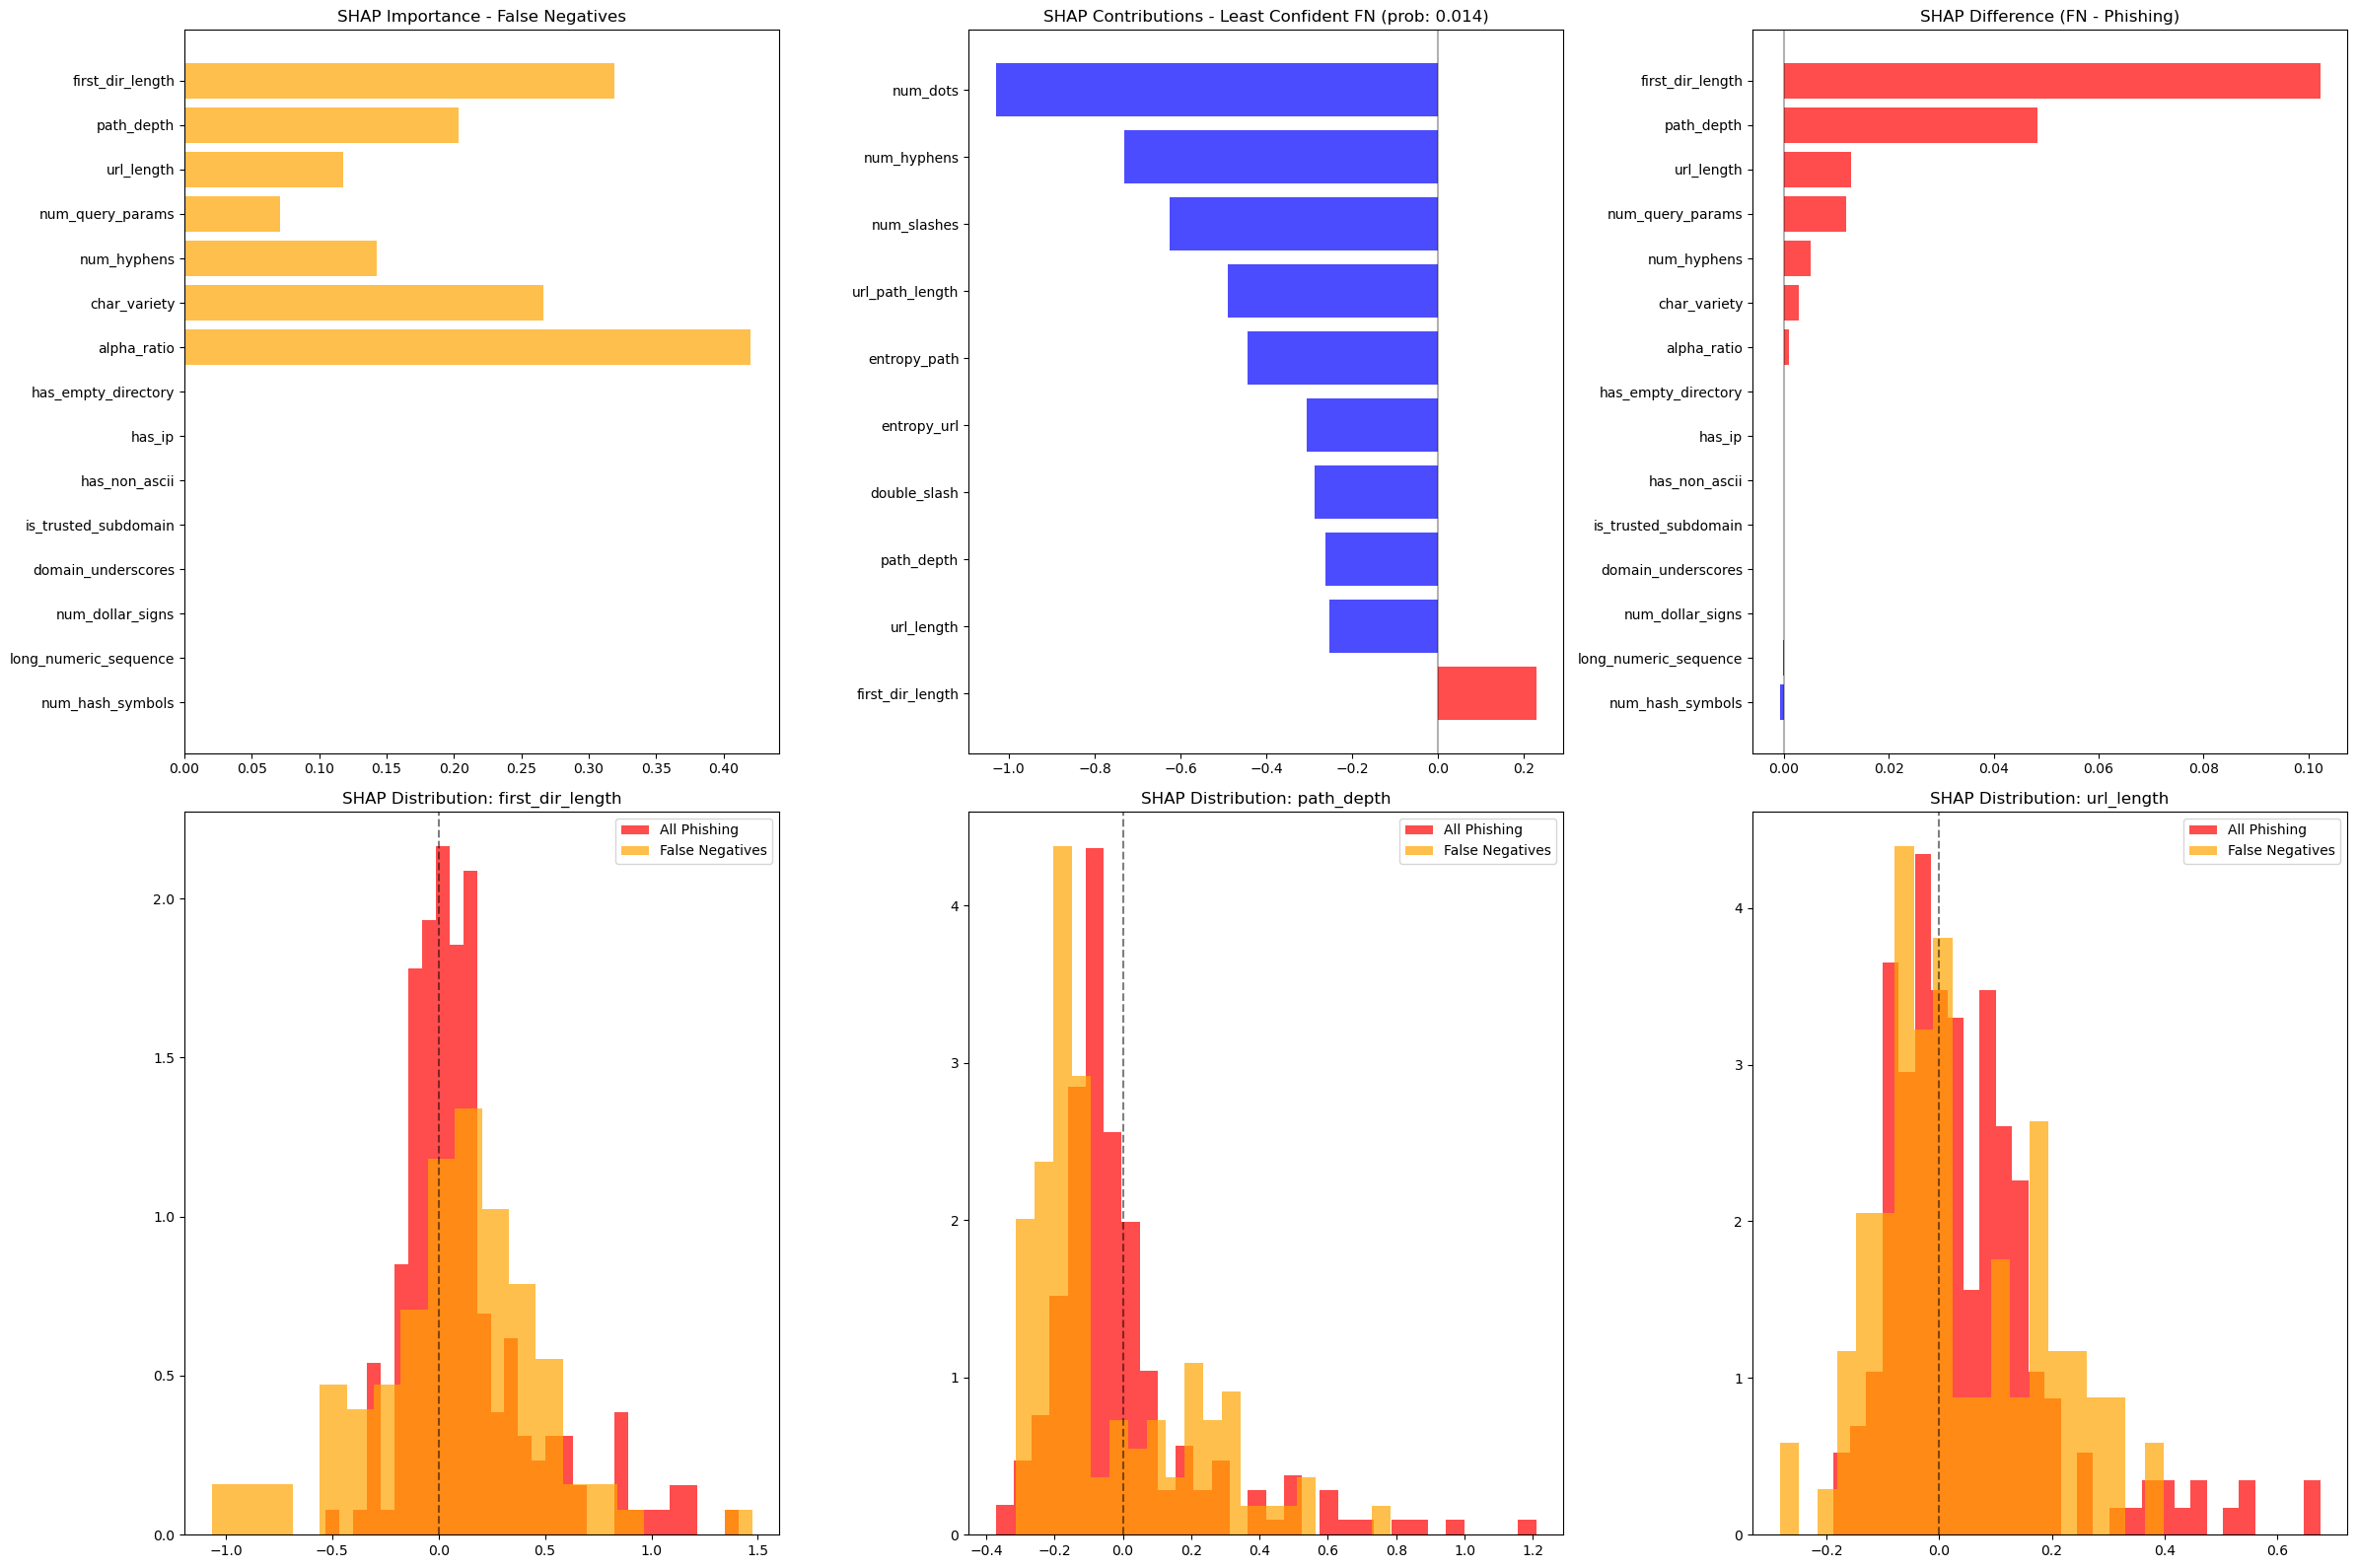

In [15]:
print("SHAP for FNs")

explainer = shap.TreeExplainer(xgboost_model)
shap_available = True
shap_available = False

if len(fn_indices) > 0: #there are FNs
    # sample for analysis
    max_fn_samples = min(100, len(fn_indices))
    fn_sample_indices = np.random.choice(fn_indices, max_fn_samples, replace=False)
    X_fn_sample = X_val.iloc[fn_sample_indices]
    
    phishing_indices = np.where(y_val == 1)[0]
    max_phishing_samples = min(200, len(phishing_indices))
    phishing_sample_indices = np.random.choice(phishing_indices, max_phishing_samples, replace=False)
    X_phishing_sample = X_val.iloc[phishing_sample_indices]
    
    shap_values_fn = explainer.shap_values(X_fn_sample)
    shap_values_phishing = explainer.shap_values(X_phishing_sample)
    
    mean_shap_fn = np.abs(shap_values_fn).mean(axis=0)
    mean_shap_phishing = np.abs(shap_values_phishing).mean(axis=0)
    
    shap_analysis = pd.DataFrame({
        'feature': X.columns,
        'shap_fn': mean_shap_fn,
        'shap_phishing': mean_shap_phishing,
        'shap_diff': mean_shap_fn - mean_shap_phishing,
        'mean_effect_fn': shap_values_fn.mean(axis=0)
    }).sort_values('shap_diff', ascending=False)
    
    fig, axes = plt.subplots(2, 3, figsize=(24, 16))
    
    # SHAP importance graph
    top_15 = shap_analysis.head(15)
    axes[0, 0].barh(range(len(top_15)), top_15['shap_fn'], color='orange', alpha=0.7)
    axes[0, 0].set_yticks(range(len(top_15)))
    axes[0, 0].set_yticklabels(top_15['feature'])
    axes[0, 0].set_title('SHAP Importance - False Negatives')
    axes[0, 0].invert_yaxis()
    
    # SHAP contributions for FNs 
    fn_probabilities = xgb_val_proba[fn_sample_indices]
    least_confident_idx = np.argmin(fn_probabilities)
    least_confident_prob = fn_probabilities[least_confident_idx]
    
    case_shap = shap_values_fn[least_confident_idx]
    case_features = pd.DataFrame({
        'feature': X.columns,
        'shap_value': case_shap
    }).sort_values('shap_value', key=abs, ascending=False).head(10)
    
    colors = ['red' if x > 0 else 'blue' for x in case_features['shap_value']]
    axes[0, 1].barh(range(len(case_features)), case_features['shap_value'], color=colors, alpha=0.7)
    axes[0, 1].set_yticks(range(len(case_features)))
    axes[0, 1].set_yticklabels(case_features['feature'])
    axes[0, 1].set_title(f'SHAP Contributions - Least Confident FN (prob: {least_confident_prob:.3f})')
    axes[0, 1].axvline(0, color='black', linestyle='-', alpha=0.3)
    axes[0, 1].invert_yaxis()
    
    # SHAP difference graph
    axes[0, 2].barh(range(len(top_15)), top_15['shap_diff'], 
                   color=['red' if x > 0 else 'blue' for x in top_15['shap_diff']], alpha=0.7)
    axes[0, 2].set_yticks(range(len(top_15)))
    axes[0, 2].set_yticklabels(top_15['feature'])
    axes[0, 2].set_title('SHAP Difference (FN - Phishing)')
    axes[0, 2].axvline(0, color='black', linestyle='-', alpha=0.3)
    axes[0, 2].invert_yaxis()
    
    # SHAP distributions for top 3 features
    for i, feature in enumerate(top_15.head(3)['feature']):
        feature_idx = list(X.columns).index(feature)
        fn_shap = shap_values_fn[:, feature_idx]
        phishing_shap = shap_values_phishing[:, feature_idx]
        
        ax = axes[1, i]
        ax.hist(phishing_shap, bins=30, alpha=0.7, label='All Phishing', density=True, color='red')
        ax.hist(fn_shap, bins=20, alpha=0.7, label='False Negatives', density=True, color='orange')
        ax.axvline(0, color='black', linestyle='--', alpha=0.5)
        ax.set_title(f'SHAP Distribution: {feature}')
        ax.legend()
    
    plt.tight_layout()
    plt.savefig('xgb_shap_fn_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()
    

else:
    print("no FNs")

In [16]:

LOWER_THRESHOLD = 0.1

UPPER_THRESHOLD = 0.7467
def classify_url_xgboost(url, model=xgboost_model, trusted_domains=trusted_domains_set, feature_extractor=extract_features_vectorized):
    
    
    
    try:
        url_df = pd.DataFrame({'url': [url]})
        features = feature_extractor(url_df['url'], trusted_domains)
        
        is_trusted = features['is_trusted_domain'].iloc[0] == 1
        
        if is_trusted:
            proba = 0.01
            decision = "legitimate"
            confidence = "high"
        else:
            proba = model.predict_proba(features)[0, 1]
            
            if proba <= LOWER_THRESHOLD:
                decision = "legitimate"
                confidence = "high" if proba <= 0.05 else "medium"
            elif proba >= UPPER_THRESHOLD:
                decision = "phishing" 
                confidence = "high" if proba >= 0.85 else "medium"
            else:
                decision = "human_review"
                confidence = "uncertain"
        
        return {
            "url": url,
            "decision": decision,
            "probability": round(proba, 4),
            "confidence": confidence,
            "thresholds": {"lower": LOWER_THRESHOLD, "upper": UPPER_THRESHOLD}
        }
        
    except Exception as e:
        return {"error": f"Classification failed: {str(e)}"}

test_urls = [
    "https://google.com",
    "https://www.google.com/search?q=test", 
    "https://github.com/user/repo",
    "http://suspicious-site-12345.com/login.php",
    "https://microsoft.com",
    "https://phishing-attempt.com/fake-bank-login",
    "https://www.xerblade.com/p/detective-conan-important-episode-list.html?m=0"
]

print("XGBoost URL Classification Results:")
print("=" * 50)

for test_url in test_urls:
    result = classify_url_xgboost(test_url)
    if "error" not in result:
        print(f"{result['decision']:<12} | {result['probability']:<6} | {test_url[:40]}...")
    else:
        print(f"Error: {result['error']}")
        break

print(f"\nThresholds: Lower={LOWER_THRESHOLD}, Upper={UPPER_THRESHOLD}")
print("Classifications: legitimate | human_review | phishing")

# Set as default classifier
classify_url = classify_url_xgboost

XGBoost URL Classification Results:
legitimate   | 0.01   | https://google.com...
legitimate   | 0.01   | https://www.google.com/search?q=test...
legitimate   | 0.01   | https://github.com/user/repo...
phishing     | 0.9997000098228455 | http://suspicious-site-12345.com/login.p...
legitimate   | 0.01   | https://microsoft.com...
phishing     | 0.9818000197410583 | https://phishing-attempt.com/fake-bank-l...
human_review | 0.2662000060081482 | https://www.xerblade.com/p/detective-con...

Thresholds: Lower=0.1, Upper=0.7467
Classifications: legitimate | human_review | phishing
